# Experiment 1: 3-channel phone audio -> speaker position

Question: from three single-microphone phones on the floor, how close can we predict where the speaker stands?

This notebook sets up the data. A `WindowedSessions` dataset cuts the synced recordings into windows and pairs each window
with the speaker's floor position at the window centre. Batches come from a normal PyTorch `DataLoader`.

In [1]:
from pathlib import Path
import csv, json

import numpy as np
import torch
from scipy.io import wavfile
from scipy.signal import butter, resample_poly, sosfiltfilt
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt

# ---- knobs ----
WINDOW_LEN = 1.0      # seconds of audio in each window
STEP_LEN = 0.5        # seconds between window starts (STEP_LEN < WINDOW_LEN: windows overlap)
BATCH_SIZE = 32
SESSIONS = [1, 2, 3]
SKIP_INTRO = True     # skip the start claps and the talking before them (meta.json: usable_from_s)
MAX_LABEL_GAP = 0.15  # s; drop a window if no tracked position lies this close to its centre
SR_OUT = 16000        # audio is resampled from 48 kHz to this (speech needs no more; 1 sample = 2.1 cm of path difference)
BANDPASS = (300, 4000)  # Hz, zero-phase filter applied to every channel the same way; None = leave the band alone
SILENCE_DB = None     # drop windows whose loudest channel is below this level (dB re full scale); None = keep all

DATASET_DIR = Path("../presets/apartment/dataset")

## The dataset

* Audio: `audio_abc.wav`, 48 kHz, 3 channels (phone A, B, C), already clock-aligned. Each session is loaded once, **resampled to `SR_OUT` (16 kHz)** and **band-passed to `BANDPASS`** (300-4000 Hz). Both steps are zero-phase and applied to the whole recording before windowing (no edge effects per window) and identically to all channels, so they add no delay between phones.
* Silence: every window gets a level, `level_db` = rms of its loudest channel in dB re full scale. `SILENCE_DB` drops windows below a threshold; leave it `None` to keep everything and measure how much silence hurts.
* Label: the floor position `(x, y)` in meters (rug frame, origin at corner R2), taken from `positions.csv` **at the window centre** (linear interpolation between the 10 Hz rows). Rows with no position (`lost`) are skipped, and a window is dropped when the nearest valid row is more than `MAX_LABEL_GAP` away.
* An item is `audio` (3, WINDOW_LEN * SR_OUT) float32 and `xy` (2,) float32 in meters. A batch also carries `level_db`, `session` and `t_center` (seconds into the session's audio), so a result can be traced back.

In [2]:
def preprocess(audio_i16, sr_in, sr_out, bandpass):
    # (samples, 3) int16 at sr_in -> (3, samples) float32 at sr_out, band-passed (zero phase)
    out = []
    for c in range(audio_i16.shape[1]):
        x = audio_i16[:, c].astype(np.float32) / 32768.0
        if sr_out != sr_in:
            g = np.gcd(sr_in, sr_out)
            x = resample_poly(x, sr_out // g, sr_in // g).astype(np.float32)
        if bandpass:
            x = sosfiltfilt(butter(4, bandpass, "bandpass", fs=sr_out, output="sos"), x).astype(np.float32)
        out.append(x)
    return np.stack(out)


class WindowedSessions(Dataset):
    def __init__(self, root=DATASET_DIR, sessions=SESSIONS, window_len=WINDOW_LEN, step_len=STEP_LEN,
                 skip_intro=SKIP_INTRO, max_label_gap=MAX_LABEL_GAP, sr_out=SR_OUT, bandpass=BANDPASS, silence_db=SILENCE_DB):
        self.window_len, self.step_len, self.sr = window_len, step_len, sr_out
        self.audio, self.sessions, self.phones = {}, {}, None
        self.W = round(window_len * sr_out)
        S = round(step_len * sr_out)
        index = []                                    # (session, start sample, centre time s, x m, y m, level dB)
        for n in sessions:
            d = Path(root) / f"session{n}"
            sr_in, raw = wavfile.read(d / "audio_abc.wav", mmap=True)       # (samples, 3) int16
            meta = json.load(open(d / "meta.json"))
            x = preprocess(raw, sr_in, sr_out, bandpass)                    # (3, samples)
            self.audio[n] = x
            self.phones = {p: tuple(v) for p, v in meta["phones_xy_m"].items()}
            rows = [r for r in csv.DictReader(open(d / "positions.csv")) if r["x_m"] != ""]
            t = np.array([float(r["t_audio_s"]) for r in rows])
            xy = np.array([[float(r["x_m"]), float(r["y_m"])] for r in rows])
            self.sessions[n] = dict(t=t, xy=xy, usable_from=meta["usable_from_s"] if skip_intro else 0.0)

            cs = np.concatenate([np.zeros((3, 1)), np.cumsum(x.astype(np.float64) ** 2, axis=1)], axis=1)
            first = round(self.sessions[n]["usable_from"] * sr_out)
            for start in range(first, x.shape[1] - self.W + 1, S):
                tc = (start + self.W / 2) / sr_out
                k = np.searchsorted(t, tc)
                near = min((abs(t[j] - tc) for j in (k - 1, k) if 0 <= j < len(t)), default=np.inf)
                if near > max_label_gap:
                    continue
                level = 10 * np.log10(((cs[:, start + self.W] - cs[:, start]) / self.W).max() + 1e-12)
                if silence_db is not None and level < silence_db:
                    continue
                index.append((n, start, tc, np.interp(tc, t, xy[:, 0]), np.interp(tc, t, xy[:, 1]), level))
        self.index = index

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        n, start, tc, x, y, level = self.index[i]
        return dict(audio=torch.from_numpy(self.audio[n][:, start:start + self.W].copy()), xy=torch.tensor([x, y], dtype=torch.float32),
                    level_db=torch.tensor(level, dtype=torch.float32), session=n, t_center=tc)

    def summary(self):
        for n in self.sessions:
            k = sum(1 for r in self.index if r[0] == n)
            print(f"session {n}: {k} windows")
        print(f"total {len(self)} windows of {self.window_len} s, step {self.step_len} s, {self.sr} Hz")


ds = WindowedSessions()
ds.summary()
loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
batch = next(iter(loader))
print({k: (tuple(v.shape), v.dtype) if torch.is_tensor(v) else type(v) for k, v in batch.items()})

session 1: 1001 windows
session 2: 1136 windows
session 3: 826 windows
total 2963 windows of 1.0 s, step 0.5 s, 16000 Hz
{'audio': ((32, 3, 16000), torch.float32), 'xy': ((32, 2), torch.float32), 'level_db': ((32,), torch.float32), 'session': ((32,), torch.int64), 't_center': ((32,), torch.float64)}


## Checks

In [3]:
# the window really is the audio at that time, and the label is the position at the window centre
item = ds[100]
n, start, tc, x, y, level = ds.index[100]
print("session", n, f"window {start / ds.sr:.2f}-{start / ds.sr + ds.window_len:.2f} s, centre {tc:.2f} s, position ({x:.3f}, {y:.3f}) m, level {level:.1f} dB")
print("audio", tuple(item["audio"].shape), "rms per channel", item["audio"].pow(2).mean(1).sqrt().numpy().round(4))
assert np.allclose(item["xy"].numpy(), [x, y])
assert np.array_equal(item["audio"].numpy(), ds.audio[n][:, start:start + ds.W])
assert item["audio"].shape == (3, round(WINDOW_LEN * SR_OUT))
print("ok")

session 1 window 68.42-69.42 s, centre 68.92 s, position (1.330, 0.777) m, level -26.5 dB
audio (3, 16000) rms per channel [0.0471 0.0231 0.025 ]
ok


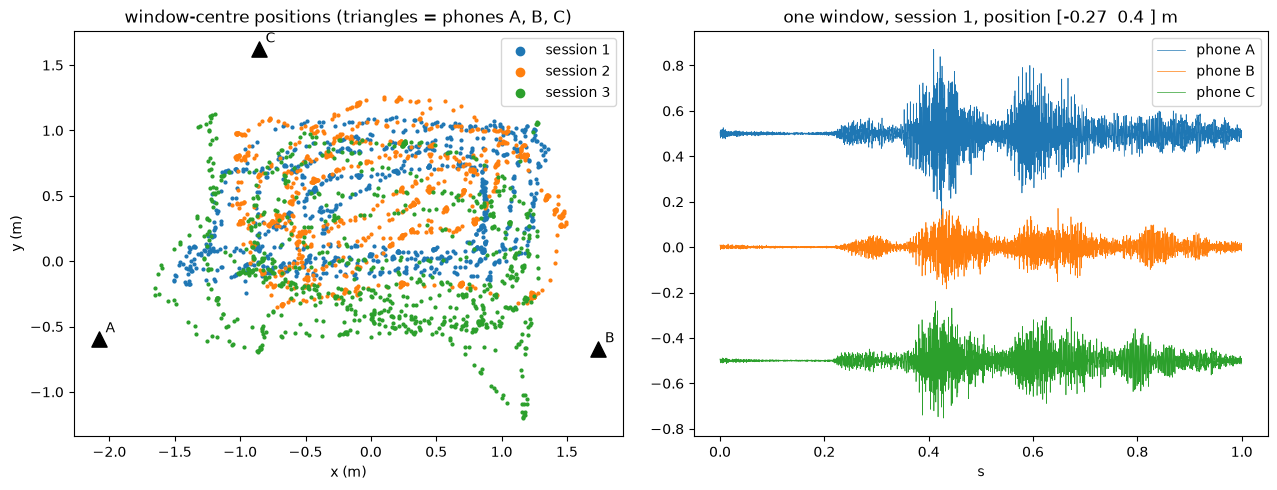

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
xy = np.array([r[3:5] for r in ds.index])
sess = np.array([r[0] for r in ds.index])
for n in SESSIONS:
    ax[0].scatter(*xy[sess == n].T, s=4, label=f"session {n}")
for p, (px, py) in ds.phones.items():
    ax[0].scatter(px, py, marker="^", s=120, c="k"); ax[0].annotate(p, (px, py), xytext=(5, 5), textcoords="offset points")
ax[0].set_aspect("equal"); ax[0].set_xlabel("x (m)"); ax[0].set_ylabel("y (m)"); ax[0].legend(markerscale=3)
ax[0].set_title("window-centre positions (triangles = phones A, B, C)")
a = batch["audio"][0].numpy(); t = np.arange(a.shape[1]) / ds.sr
for c, name in enumerate("ABC"):
    ax[1].plot(t, a[c] + 0.5 * (1 - c), lw=0.5, label=f"phone {name}")
ax[1].set_title(f"one window, session {batch['session'][0].item()}, position {batch['xy'][0].numpy().round(2)} m")
ax[1].set_xlabel("s"); ax[1].legend()
plt.tight_layout()

## Silence

You pause while reading, and a pause has a position label but no speaker in it. The histogram shows how the window levels split. Choose `SILENCE_DB` from it (a valley between the two humps), or keep everything and compare results with and without the quiet windows.

level percentiles (dB): {5: np.float64(-36.5), 25: np.float64(-31.6), 50: np.float64(-29.6), 75: np.float64(-27.6), 95: np.float64(-24.8)}


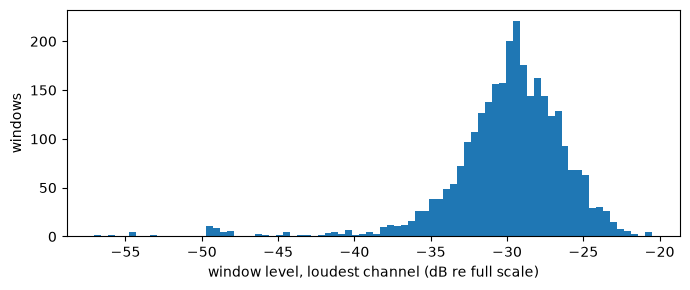

In [5]:
lv = np.array([r[5] for r in ds.index])
print("level percentiles (dB):", dict(zip([5, 25, 50, 75, 95], np.percentile(lv, [5, 25, 50, 75, 95]).round(1))))
plt.figure(figsize=(7, 3)); plt.hist(lv, bins=80); plt.xlabel("window level, loudest channel (dB re full scale)"); plt.ylabel("windows")
plt.tight_layout()

# Part 2: exploring the delays between the phones

Before predicting anything, we look at whether the audio contains a usable timing signal at all, since the TDOA method depends on it. This section:
1. explains GCC-PHAT, the tool that measures the delay between two phones, and runs it on every window;
2. compares the measured delays with the **true** ones (known from the camera and the phone positions);
3. checks the code on a synthetic delay;
4. asks whether a steady delay is hiding in the noise, and whether a **clock offset or drift** between the phones could be the reason it is not found.

Part 3 then uses these delays to predict positions.

In [6]:
# the label of every window, in the dataset's order (rows of ds.index: session, start, centre time, x, y, level)
truth = np.array([r[3:5] for r in ds.index])           # meters
sess = np.array([r[0] for r in ds.index])
t_centre = np.array([r[2] for r in ds.index])
P = np.array([ds.phones[p] for p in "ABC"])             # phone positions on the floor, meters
C_SOUND = 343.0                                         # m/s
MOUTH_Z = 1.45                                          # m, assumed height of the voice above the phones on the floor

def err_cm(pred):
    return np.linalg.norm(pred - truth, axis=1) * 100

def report(name, err):
    row = lambda e: f"median {np.median(e):6.1f}   mean {e.mean():6.1f}   p90 {np.percentile(e, 90):6.1f}"
    print(f"{name:<34} all: {row(err)}")
    for n in SESSIONS:
        print(f"{'':<34} s{n}:  {row(err[sess == n])}")

## GCC-PHAT: measuring the delay between two phones

### Idea
A voice at position *s* reaches phone *i* after `distance(s, phone_i) / 343 m/s`. The three phones record the same voice at slightly different times. We cannot know when the voice was *emitted*, but we can measure the **difference** in arrival time between two phones. For the pair (i, j):

&nbsp;&nbsp;&nbsp;&nbsp;`tau_ij = (distance(s, phone_i) - distance(s, phone_j)) / 343`

The phones are 2.5 to 3.9 m apart, so `tau` is at most about 11 ms. One millisecond is 34 cm of path difference. The phone clocks were aligned earlier from the start claps (about 0.5 ms; drift later in each session is not corrected), so a delay between two *channels* can be read as a delay between two *places*.

### How GCC-PHAT works
*Generalized cross-correlation with phase transform*, for each of the pairs A-B, A-C and B-C, in every window:
1. Take the Fourier transform of both channels. Delay in time is a phase that grows with frequency, `exp(-j 2 pi f tau)`.
2. Multiply one by the conjugate of the other. What is left is the delay's phase, plus the sound's own spectrum.
3. **PHAT**: divide by the magnitude, so only the phase survives. Every frequency then counts equally. Plain cross-correlation is dominated by the loudest low frequencies and smears under echoes; whitening gives a much sharper peak.
4. Keep only 300-4000 Hz (where the voice is) and transform back. The result is a curve over possible delays, and its **highest peak** is the delay estimate. Its height (about 0 for noise up to 1 for a perfect match) tells us how much to trust the estimate.
5. Transform back onto a 4x finer time grid, so the peak is found to a quarter of a sample (0.016 ms, 0.5 cm), not to one sample (2 cm).

We only look for peaks within the physically possible range for each pair (the distance between the phones divided by 343 m/s, plus a small margin). Anything outside is not a direct path.

The second half of the method (turning delays into a position) comes later, in Part 3. Here we only ask whether the audio contains usable delays.

In [7]:
NFFT, INTERP = 32768, 4                 # FFT length (>= 2 x window); the delay curve is made 4x finer than the sample spacing
BAND = (300, 4000)                      # Hz, the part of the spectrum that goes into the phase
PAIRS = [(0, 1), (0, 2), (1, 2)]        # A-B, A-C, B-C: tau_ij = arrival at i minus arrival at j
PAIR_NAMES = ["A-B", "A-C", "B-C"]
MARGIN = 0.0003                         # s, slack added to each pair's physical delay range

fs = ds.sr
max_tau = [np.linalg.norm(P[i] - P[j]) / C_SOUND + MARGIN for i, j in PAIRS]
freqs = np.fft.rfftfreq(NFFT, 1 / fs)
band = (freqs >= BAND[0]) & (freqs <= BAND[1])
hann = np.hanning(ds.W).astype(np.float32)

def gcc_phat(audio):
    # audio (B, 3, W) -> for each pair: delay curve (B, n_lags), plus the lag axis in seconds
    X = np.fft.rfft(audio * hann, n=NFFT, axis=-1)                       # (B, 3, bins)
    curves = []
    for (i, j), mt in zip(PAIRS, max_tau):
        R = X[:, i] * np.conj(X[:, j])
        R = R / (np.abs(R) + 1e-12) * band                               # PHAT: keep the phase only, inside the band
        cc = np.fft.irfft(R, n=INTERP * NFFT, axis=-1) * (INTERP * NFFT) / (2 * band.sum())   # 1.0 = perfect match
        L = int(np.ceil(mt * fs * INTERP))
        curves.append(np.concatenate([cc[:, -L:], cc[:, :L + 1]], axis=-1))
    return curves

lags = [np.arange(-((x.shape[-1] - 1) // 2), (x.shape[-1] - 1) // 2 + 1) / (INTERP * fs) for x in gcc_phat(np.zeros((1, 3, ds.W), np.float32))]

curves = [[] for _ in PAIRS]
for b in DataLoader(ds, batch_size=64, shuffle=False):
    for k, c in enumerate(gcc_phat(b["audio"].numpy())):
        curves[k].append(c.astype(np.float32))
curves = [np.concatenate(c) for c in curves]                             # per pair: (windows, n_lags)
tau_meas = np.stack([lags[k][curves[k].argmax(1)] for k in range(3)], axis=1)   # seconds, (windows, 3)
peak = np.stack([curves[k].max(1) for k in range(3)], axis=1)            # peak height per pair
print("delay curves:", [c.shape for c in curves])
print("median peak height per pair (A-B, A-C, B-C):", np.median(peak, axis=0).round(3))

delay curves: [(2963, 1467), (2963, 985), (2963, 1333)]
median peak height per pair (A-B, A-C, B-C): [0.083 0.087 0.087]


### How good are the measured delays?
Here we do not need the solve yet. Because we know where the speaker really was (camera) and where the phones are, we can compute the **true** delay for every window and compare. This isolates the audio measurement from everything after it.

The first picture is the delay curve of one window for each pair, with the true delay (black dashed) and the measured peak (red). The histograms show the error over all windows, in milliseconds (1 ms = 34 cm).

share of delays within 0.3 ms (10 cm) of the truth, per pair (A-B, A-C, B-C): [0.04 0.13 0.05]
  session 1: median |delay error| per pair, ms: [4.52 1.91 3.61]
  session 2: median |delay error| per pair, ms: [3.61 1.4  2.91]
  session 3: median |delay error| per pair, ms: [4.45 1.35 3.39]


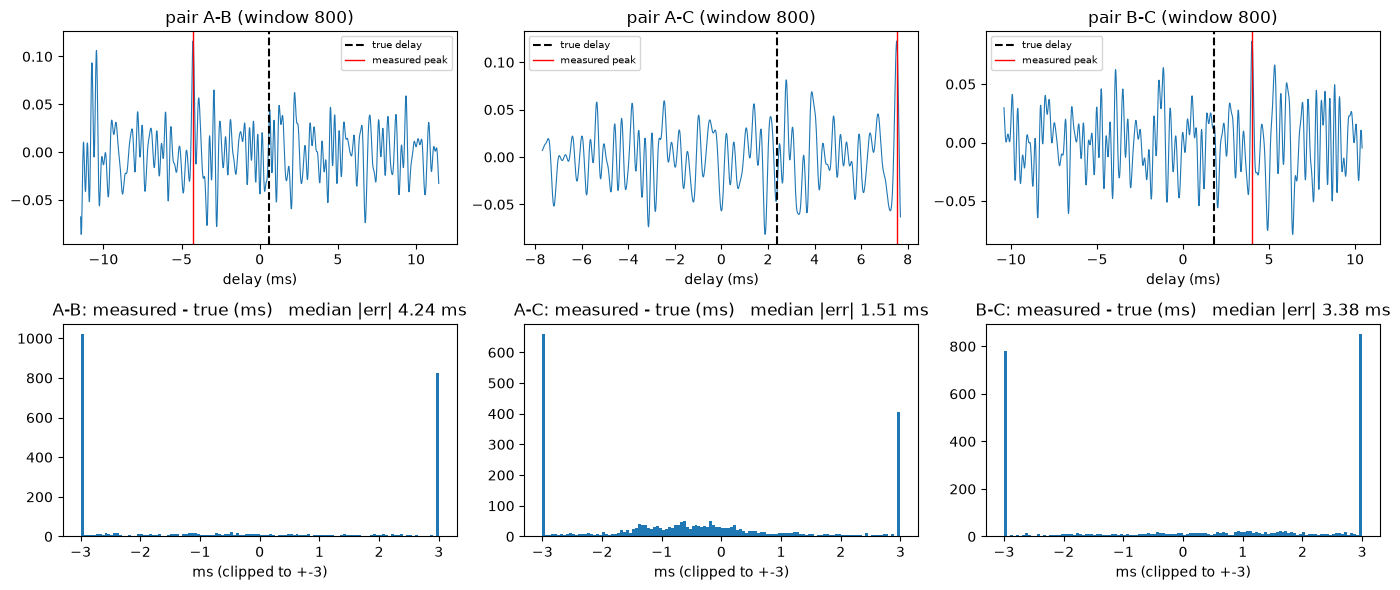

In [8]:
def true_tau(xy):
    d = np.sqrt(((xy[:, None, :] - P[None]) ** 2).sum(-1) + MOUTH_Z ** 2)       # distance from the voice to each phone
    return np.stack([(d[:, i] - d[:, j]) / C_SOUND for i, j in PAIRS], axis=1)

tau_true = true_tau(truth)
dtau_ms = (tau_meas - tau_true) * 1000

w = 800
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for k in range(3):
    ax[0, k].plot(lags[k] * 1000, curves[k][w], lw=0.8)
    ax[0, k].axvline(tau_true[w, k] * 1000, c="k", ls="--", label="true delay")
    ax[0, k].axvline(tau_meas[w, k] * 1000, c="r", lw=1, label="measured peak")
    ax[0, k].set_title(f"pair {PAIR_NAMES[k]} (window {w})"); ax[0, k].set_xlabel("delay (ms)"); ax[0, k].legend(fontsize=7)
    ax[1, k].hist(np.clip(dtau_ms[:, k], -3, 3), bins=120)
    ax[1, k].set_title(f"{PAIR_NAMES[k]}: measured - true (ms)   median |err| {np.median(np.abs(dtau_ms[:, k])):.2f} ms")
    ax[1, k].set_xlabel("ms (clipped to +-3)")
plt.tight_layout()
good = np.abs(dtau_ms) < 0.3
print("share of delays within 0.3 ms (10 cm) of the truth, per pair (A-B, A-C, B-C):", good.mean(0).round(2))
for n in SESSIONS:
    print(f"  session {n}: median |delay error| per pair, ms:", np.median(np.abs(dtau_ms[sess == n]), axis=0).round(2))

### Is the GCC-PHAT code correct? (synthetic test)
A bug (a flipped sign, a wrong lag axis) would also give bad delays, so we check the code on a signal with known delays: the same band-limited noise, with channel B delayed by 20 samples and channel C advanced by 35. The expected delays `t_A - t_B`, `t_A - t_C`, `t_B - t_C` are -20, +35 and +55 samples.

In [9]:
from scipy.signal import butter as _butter, sosfiltfilt as _sosfiltfilt
_s = np.random.default_rng(1).standard_normal(ds.W + 400)
_s = _sosfiltfilt(_butter(4, BAND, "bandpass", fs=fs, output="sos"), _s)
_a = np.stack([_s[200:200 + ds.W], _s[180:180 + ds.W], _s[235:235 + ds.W]]).astype(np.float32)[None]
for k, c in enumerate(gcc_phat(_a)):
    print(f"{PAIR_NAMES[k]}: measured {lags[k][c[0].argmax()] * fs:+.2f} samples")

A-B: measured -20.00 samples
A-C: measured +35.00 samples
B-C: measured +55.00 samples


### Is a steady delay hiding in the noise? (aligned average)
The single-window curves look like noise. If a consistent delay exists, it should appear when many windows are combined. We shift every window's curve so that **its true delay sits at 0**, then average over all windows. A real, correctly timed direct path would then show as one tall peak at offset 0. A peak somewhere else would mean a constant offset (for example from the clocks). The ratio compares the tallest point with the spread of the rest of the curve; by chance alone, about 3 is normal.

In [10]:
per_ms = INTERP * fs / 1000
OFF = np.arange(int(-8 * per_ms), int(8 * per_ms) + 1)
def aligned(k, rows):
    acc, cnt = np.zeros(len(OFF)), np.zeros(len(OFF))
    for q in rows:
        idx = int(round((tau_true[q, k] - lags[k][0]) * INTERP * fs)) + OFF
        ok = (idx >= 0) & (idx < curves[k].shape[1])
        acc[ok] += curves[k][q][idx[ok]]; cnt[ok] += 1
    return acc / np.maximum(cnt, 1)
for k in range(3):
    m = aligned(k, range(len(truth)))
    j = m.argmax()
    print(f"{PAIR_NAMES[k]}: tallest point at offset {OFF[j] / per_ms:+.2f} ms (0 = true delay), ratio to the rest {m[j] / m[np.abs(OFF / per_ms) > 3].std():.1f}")

A-B: tallest point at offset -2.50 ms (0 = true delay), ratio to the rest 3.3
A-C: tallest point at offset -1.08 ms (0 = true delay), ratio to the rest 3.8
B-C: tallest point at offset +1.06 ms (0 = true delay), ratio to the rest 3.1


### Offset against time: is there drift?
Same alignment, but kept **per window and over time** instead of averaged over the whole session. Each panel is one session and one pair of phones. Horizontal axis: time in the session. Vertical axis: offset from the true delay (ms). Colour: how strongly the phones' audio correlates at that offset, averaged over 30 windows (15 s) so that real structure stands out from noise.

How to read it:
* a bright **horizontal line at 0**: clocks in sync, delay found;
* a bright horizontal line **elsewhere**: a constant clock offset;
* a bright **tilted line**: clock **drift** (one phone's clock running fast or slow). Drift of 20 ppm would move a line by 10 ms over 500 s, across the whole panel;
* **random streaks**: noise, no steady delay.

The first minute after the claps is the cleanest test. The clocks were set from those claps (about 0.5 ms), and drift there is a fraction of a millisecond, so a working method should show the line at 0 early on.

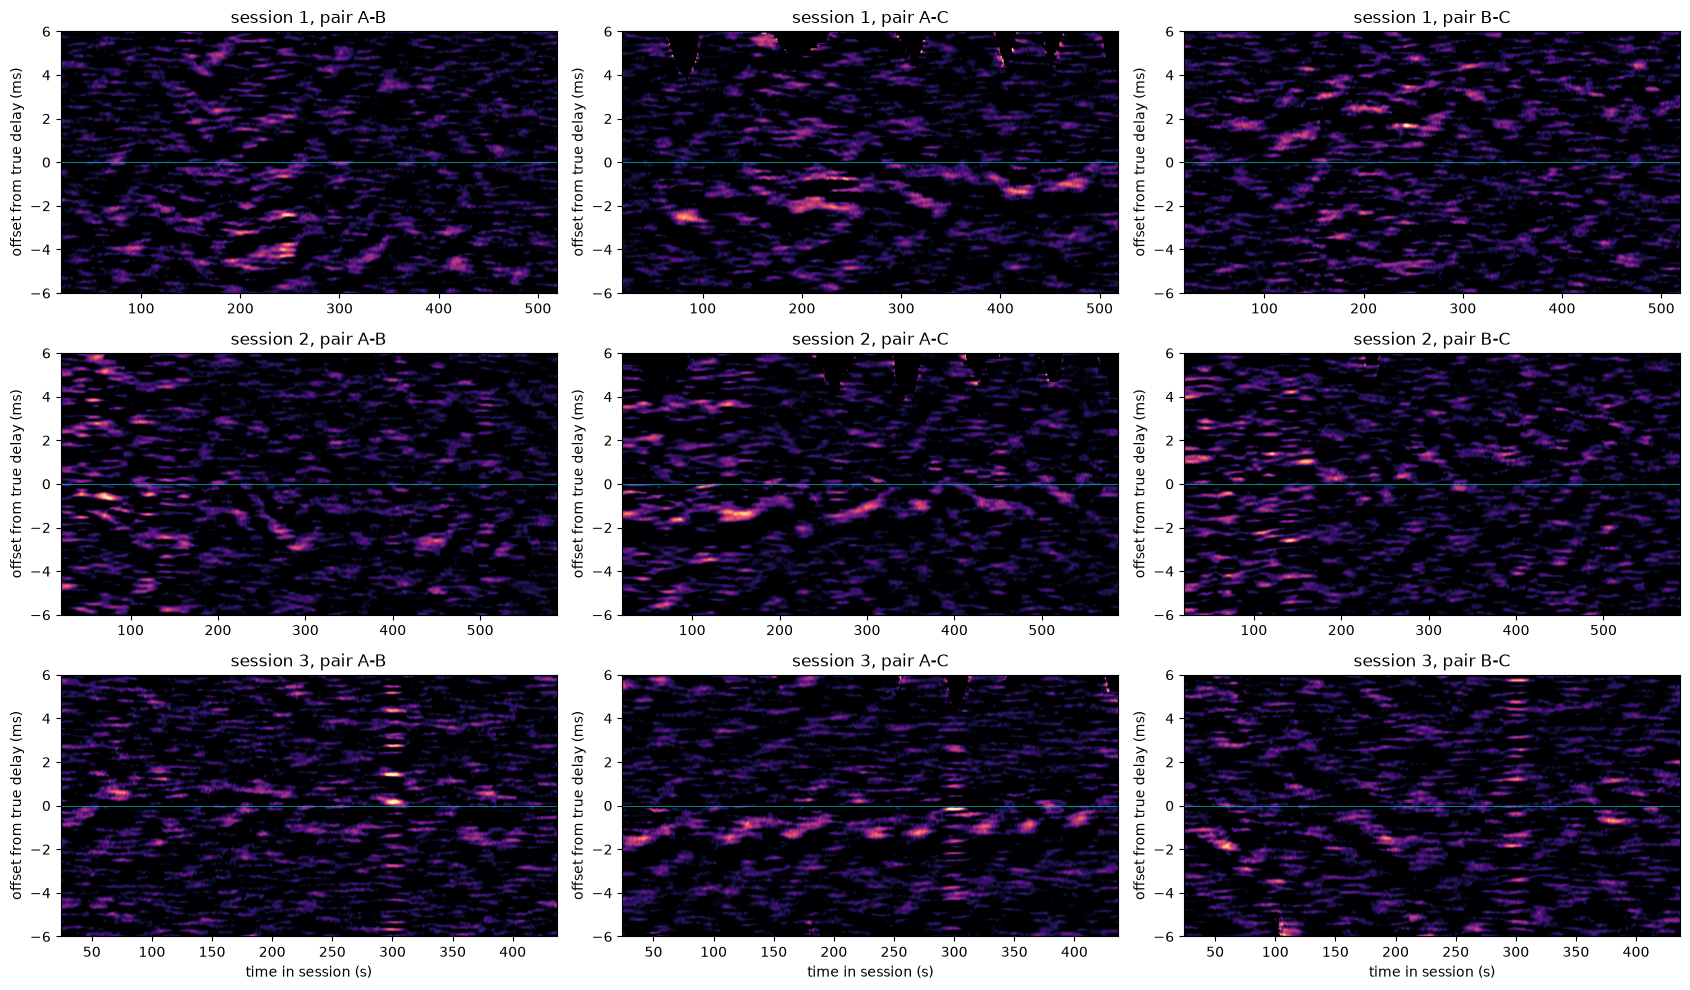

In [11]:
OFFS = np.arange(int(-6 * per_ms), int(6 * per_ms) + 1)
SMOOTH = 30                                           # windows averaged along time
fig, ax = plt.subplots(3, 3, figsize=(17, 10))
for si, n in enumerate(SESSIONS):
    rows = np.where(sess == n)[0]
    for k in range(3):
        Rm = np.full((len(rows), len(OFFS)), np.nan, np.float32)
        for a, q in enumerate(rows):
            idx = int(round((tau_true[q, k] - lags[k][0]) * INTERP * fs)) + OFFS
            ok = (idx >= 0) & (idx < curves[k].shape[1])
            Rm[a, ok] = curves[k][q][idx[ok]]
        ker = np.ones(SMOOTH)
        num = np.apply_along_axis(lambda v: np.convolve(v, ker, "same"), 0, np.nan_to_num(Rm))
        den = np.apply_along_axis(lambda v: np.convolve(v, ker, "same"), 0, (~np.isnan(Rm)).astype(np.float32))
        S = num / np.maximum(den, 1)
        z = (S - np.median(S)) / S.std()
        ax[si, k].imshow(z.T, aspect="auto", origin="lower", extent=[t_centre[rows][0], t_centre[rows][-1], -6, 6], cmap="magma", vmin=0, vmax=6)
        ax[si, k].axhline(0, c="c", lw=0.5)
        ax[si, k].set_title(f"session {n}, pair {PAIR_NAMES[k]}"); ax[si, k].set_ylabel("offset from true delay (ms)")
for a in ax[2]: a.set_xlabel("time in session (s)")
plt.tight_layout()

**What the picture shows** (first run)
* There is no clean line at 0 in any panel, not even in the first minute after the claps. Drift cannot explain that, because drift has hardly started there.
* There are no steep tilted lines, so no large drift (tens of ppm). A drift of a few ppm would tilt a line by only 1-2 ms over a session, comparable to the wobble in the one weak ridge, so it is not excluded, but it cannot be what makes the delays fail.
* One faint wandering ridge in pair A-C, between about -2.5 and -0.5 ms in all three sessions. It is not straight and not at 0, so it does not look like drift. Pairs A-B and B-C show nothing persistent.
* Most of each panel is random streaks: the voice is not arriving as a clean, shared signal that GCC-PHAT can time. Why (reverberation, phone audio processing, something else) is still open.

### Clap check: does GCC-PHAT work where the answer is known and the sound is sharp?
At the start of every session you clapped three times at a known spot (the camera gives where), so the true delays are known: 9 claps x 3 pairs = 27 delays. A clap is an impulse, the easiest possible sound to time, and the clock offsets between the phones were set from exactly these claps (with a different method: the **first arrival** of the sound in each recording, good to about 0.5 ms). So here the clocks and the geometry are right by construction. If GCC-PHAT misses the true delay on claps too, the weakness is in the method, not (only) in the speech.

First a table for a 100 ms window around each clap, then a sweep over window sizes (centred on the loudest sample) and over the whitening strength: PHAT exponent 1 is full PHAT, 0 is plain cross-correlation with no whitening.

In [12]:
def gcc_pairs(a, beta=1.0):
    # a (3, W) -> measured delay (s) and peak height for the pairs A-B, A-C, B-C
    W = a.shape[-1]; nfft = 1 << int(np.ceil(np.log2(2 * W)))
    fr = np.fft.rfftfreq(nfft, 1 / fs); bm = (fr >= BAND[0]) & (fr <= BAND[1])
    X = np.fft.rfft(a * np.hanning(W), n=nfft, axis=-1); out = []
    for (i, j), mt in zip(PAIRS, max_tau):
        R = X[i] * np.conj(X[j]); R = R / (np.abs(R) + 1e-12) ** beta * bm
        cc = np.fft.irfft(R, n=INTERP * nfft) * (INTERP * nfft) / (2 * bm.sum())
        L = int(np.ceil(mt * fs * INTERP)); c = np.concatenate([cc[-L:], cc[:L + 1]])
        out.append(((c.argmax() - L) / (INTERP * fs), c.max()))
    return out

def tau_at(xy_m, z):
    d = np.sqrt(((P - xy_m) ** 2).sum(1) + z ** 2)
    return [(d[i] - d[j]) / C_SOUND for i, j in PAIRS]

CLAP_Z = 1.2                                          # m, height of the hands
claps = {n: json.load(open(DATASET_DIR / f"session{n}" / "meta.json")) for n in SESSIONS}
print("100 ms window around each clap: measured - true delay, ms (peak height in brackets)")
for n in SESSIONS:
    xy = np.array(claps[n]["clap_xy_in"]) * 0.0254
    for t in claps[n]["claps_t_audio_s"]:
        m = gcc_pairs(ds.audio[n][:, int((t - 0.05) * fs):int((t + 0.05) * fs)])
        tt = tau_at(xy, CLAP_Z)
        print(f"  session {n}, clap at {t:5.1f} s: " + "   ".join(f"{PAIR_NAMES[k]} {(m[k][0] - tt[k]) * 1000:+6.2f} ({m[k][1]:.2f})" for k in range(3)))

print()
print("sweep over all 27 clap delays: median |error| and share of delays within 0.5 / 1.5 ms")
for half in (0.005, 0.015, 0.025, 0.05):
    for beta in (1.0, 0.5, 0.0):
        errs = []
        for n in SESSIONS:
            xy = np.array(claps[n]["clap_xy_in"]) * 0.0254
            for t in claps[n]["claps_t_audio_s"]:
                seg = ds.audio[n][0, int((t - 0.03) * fs):int((t + 0.03) * fs)]
                c0 = (int((t - 0.03) * fs) + np.argmax(np.abs(seg))) / fs
                m = gcc_pairs(ds.audio[n][:, int((c0 - half) * fs):int((c0 + half) * fs)], beta)
                errs += [(m[k][0] - tt_) * 1000 for k, tt_ in enumerate(tau_at(xy, CLAP_Z))]
        e = np.abs(errs)
        print(f"  window +-{half * 1000:3.0f} ms, PHAT exponent {beta:.1f}: median {np.median(e):5.2f} ms, within 0.5 ms {(e < 0.5).mean():4.0%}, within 1.5 ms {(e < 1.5).mean():4.0%}")

100 ms window around each clap: measured - true delay, ms (peak height in brackets)
  session 1, clap at   7.5 s: A-B  -1.16 (0.20)   A-C  +0.74 (0.15)   B-C  -0.41 (0.26)
  session 1, clap at  11.8 s: A-B  -0.72 (0.30)   A-C  -1.20 (0.23)   B-C  -0.51 (0.35)
  session 1, clap at  15.4 s: A-B  +0.82 (0.29)   A-C  +0.39 (0.18)   B-C  +0.10 (0.16)
  session 2, clap at  10.8 s: A-B  -8.08 (0.14)   A-C  +0.73 (0.15)   B-C +11.12 (0.13)
  session 2, clap at  13.5 s: A-B  +4.35 (0.16)   A-C  -3.59 (0.17)   B-C  -0.15 (0.17)
  session 2, clap at  16.5 s: A-B  -0.18 (0.21)   A-C  -0.14 (0.15)   B-C  +5.16 (0.17)
  session 3, clap at  14.5 s: A-B -12.24 (0.16)   A-C  +4.84 (0.23)   B-C  -6.16 (0.17)
  session 3, clap at  17.5 s: A-B -13.26 (0.16)   A-C  -8.74 (0.22)   B-C  -0.94 (0.15)
  session 3, clap at  20.6 s: A-B -11.88 (0.16)   A-C  +1.52 (0.19)   B-C  -3.97 (0.12)

sweep over all 27 clap delays: median |error| and share of delays within 0.5 / 1.5 ms
  window +-  5 ms, PHAT exponent 1.0:

**What the clap check shows** (first run)
* GCC-PHAT misses the true clap delays too. In session 1 the errors are about 0.4-1.2 ms; in sessions 2 and 3 they are often several ms and up to 13 ms, even though the clap is an impulse and the clocks were set from these very claps.
* No setting fixes it. The best case in the sweep is a median error of about 1.4 ms, with only about 20% of delays within 0.5 ms and about half within 1.5 ms. Using no whitening at all (plain cross-correlation) is no better overall, and neither are shorter or longer windows.
* So the weakness is not (only) the speech and not the clock sync: **comparing the waveforms of two phones does not find the delay reliably in this room**, even for the easiest sound. The first-arrival method used for syncing worked on the same claps (the synced dataset's clap check agrees with the geometry to about 1 ms) because it times the *start* of the sound, the direct path, instead of asking which stretch of two recordings looks most alike. In a reverberant room each phone hears the direct sound plus different strong reflections, so the whole waveforms are not similar enough for the correlation peak to be the direct path.
* Speech has no sharp start to time, so the first-arrival trick is not available for it. That is a physical limit of the setup, not a bug, and it makes timing-based features a poor bet here. Level (loudness per phone) and spectral features do not need the waveforms to match, so they are the next thing to try.

### Is it the time sync? (discussion, with the reasoning)
A natural suspicion: the clocks were aligned from the claps by *estimating* each sound's travel time (about 2 m), so a small error there could shift the channels enough to confuse GCC-PHAT. What was actually done: each phone's arrival time of the claps was measured (first arrival of the sound); the travel time from the clap spot (located by the camera) to each phone was subtracted; what remains is each phone's clock offset, and only that offset was removed. The channels therefore still carry the room's real delays, which is what TDOA needs.

Why the sync error cannot explain the failure above:
* **Size.** A 10 cm error in the clap position moves a delay by 0.3 ms; the three claps and three timing methods agreed to about 0.5 ms, and the synced dataset's own clap check lands within about 1 ms (about 17-34 cm of path). The clap-check errors reach 13 ms.
* **Shape.** A sync error is a constant shift, so all claps of a session would be off by the same amount. They are not (session 3, pair A-C: +4.8, -8.7, +1.5 ms for claps made from one spot). And a constant shift does not confuse GCC-PHAT; it only moves the peak.
* **The heatmap** would show a constant offset as a horizontal line away from 0 ms. The only candidate is the faint A-C ridge at about -1 to -2.5 ms, which might be a sync error somewhat above the 0.5 ms estimate. That is a second-order effect.

A more precise sync would still be useful if timing is pursued further: put the three phones touching, clap next to them (travel times then equal, offsets come out directly with no position estimate), and only then move them to the triangle. A light-flash reference would give zero travel time but needs a light sensor in the recording path, which audio-only phones do not have.

Our reading is that the main limit is reverberation: each phone hears the direct sound plus different strong reflections, so waveforms are not similar enough for the correlation peak to be the direct path. That is an interpretation, not measured (we did not estimate the room's reverberation time).

# Part 3: first baselines

We now measure how well position can be predicted, in two steps of increasing cleverness.

| | uses the audio? | learns from data? | what it tells us |
|---|---|---|---|
| **A. Mean position** | no | yes (one average) | the error of knowing nothing. Every other result has to beat this. |
| **B. TDOA** (GCC-PHAT, then a geometry solve) | yes | no | how far physics alone gets, with only the phone positions |

Error is the straight-line distance in **centimeters** between the predicted and the true floor position. We report the median (a typical window), the mean (hurt by bad misses) and the 90th percentile (how bad the bad ones are).

## A. Baseline: always answer with the average position

Ignore the audio. For each session, take the mean position of the **other two** sessions and answer that for every window ("leave one session out", so the answer never saw the session it is scored on).

This is the number to beat. Because the walking route stayed mostly in the middle of the room, it will not be terrible. A model has only learned something from the audio if it does clearly better.

In [13]:
pred_mean = np.zeros_like(truth)
for n in SESSIONS:
    pred_mean[sess == n] = truth[sess != n].mean(axis=0)
err_mean = err_cm(pred_mean)
report("A. mean position", err_mean)

A. mean position                   all: median   84.6   mean   87.1   p90  131.5
                                   s1:  median   79.3   mean   83.2   p90  129.7
                                   s2:  median   78.8   mean   82.4   p90  128.8
                                   s3:  median   97.7   mean   98.3   p90  145.8


## B. TDOA step 2: solve for the position (geometry)
The delays measured in Part 2 go in here.

Each measured delay says the speaker is on a **hyperbola**: all the points where the difference of the distances to two phones has that value. Two pairs give two hyperbolas that cross at the speaker. The third pair is redundant for a perfect measurement, but it helps when one measurement is off.

Method: lay a grid over the room (2 cm apart, from -3.5 to 3.5 m in x and -2.5 to 3.5 m in y). For each grid point compute the three delays it would produce, using the known phone positions and the voice height `MOUTH_Z`. Pick the point whose predicted delays best match the measured ones. The mismatch for each pair is capped at 1 ms (a *truncated* squared error), so a single wrong peak can't drag the answer far. No training is involved.

Sanity check first: feed the solver the **true** delays (computed from the camera position). It should return the true position to within the grid size. If it doesn't, the solver is wrong, not the audio.

In [14]:
CAP = 0.001                                           # s, a mismatch is not counted beyond this
gx, gy = np.arange(-3.5, 3.5 + 1e-9, 0.02), np.arange(-2.5, 3.5 + 1e-9, 0.02)
G = np.stack(np.meshgrid(gx, gy, indexing="ij"), -1).reshape(-1, 2)
tau_grid = true_tau(G)                                # (grid points, 3): the delays each grid point would give

def solve(tau):
    out = np.zeros((len(tau), 2))
    for n in range(len(tau)):
        cost = np.minimum((tau_grid - tau[n]) ** 2, CAP ** 2).sum(1)
        out[n] = G[cost.argmin()]
    return out

pred_oracle = solve(tau_true)
report("B0. solver with the TRUE delays", err_cm(pred_oracle))

B0. solver with the TRUE delays    all: median    0.8   mean    0.8   p90    1.2
                                   s1:  median    0.8   mean    0.8   p90    1.3
                                   s2:  median    0.8   mean    0.8   p90    1.3
                                   s3:  median    0.8   mean    0.8   p90    1.2


### B. Result: TDOA with the measured delays
Now the real thing: measured delays into the solver.

In [15]:
pred_tdoa = solve(tau_meas)
err_tdoa = err_cm(pred_tdoa)
report("A. mean position", err_mean)
report("B. TDOA (GCC-PHAT + solve)", err_tdoa)

A. mean position                   all: median   84.6   mean   87.1   p90  131.5
                                   s1:  median   79.3   mean   83.2   p90  129.7
                                   s2:  median   78.8   mean   82.4   p90  128.8
                                   s3:  median   97.7   mean   98.3   p90  145.8
B. TDOA (GCC-PHAT + solve)         all: median  182.5   mean  192.6   p90  347.8
                                   s1:  median  180.4   mean  200.6   p90  354.3
                                   s2:  median  178.7   mean  187.3   p90  339.1
                                   s3:  median  187.6   mean  190.2   p90  361.7


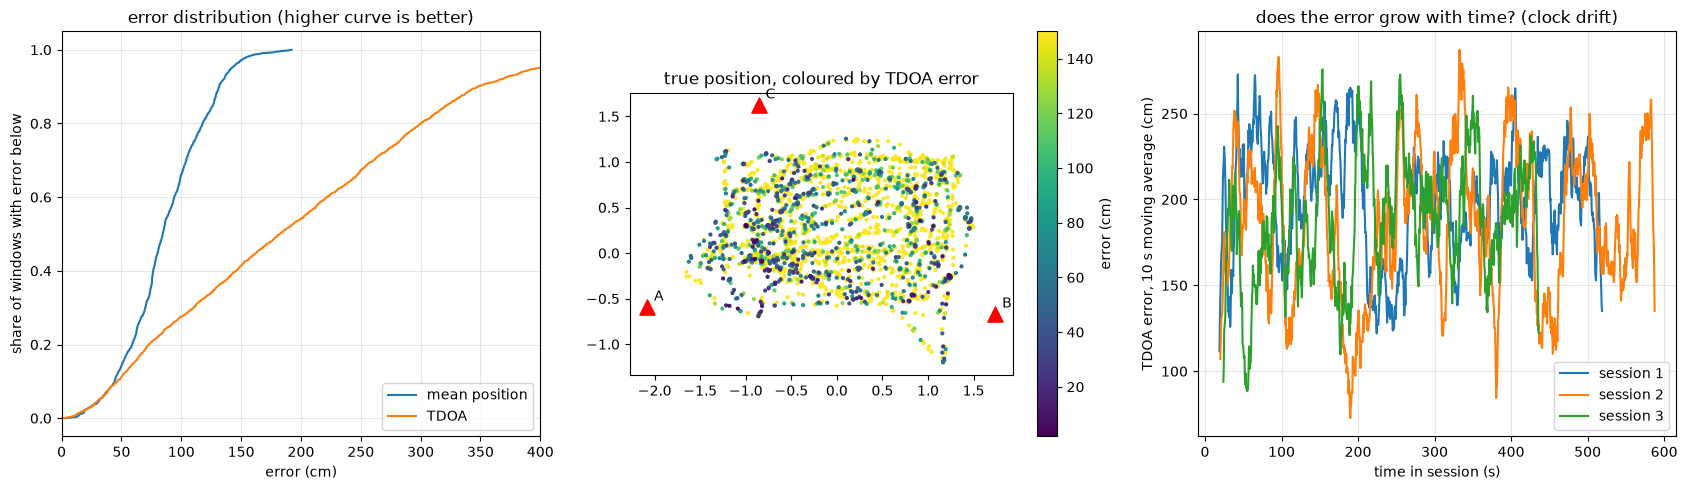

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for name, e in (("mean position", err_mean), ("TDOA", err_tdoa)):
    ax[0].plot(np.sort(e), np.arange(1, len(e) + 1) / len(e), label=name)
ax[0].set_xlim(0, 400); ax[0].set_xlabel("error (cm)"); ax[0].set_ylabel("share of windows with error below"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title("error distribution (higher curve is better)")
order = np.argsort(-err_tdoa)                            # draw the worst first, so the good windows stay visible on top
sc = ax[1].scatter(*truth[order].T, s=4, c=err_tdoa[order], cmap="viridis", vmax=150)
for p, (px, py) in ds.phones.items():
    ax[1].scatter(px, py, marker="^", s=120, c="r"); ax[1].annotate(p, (px, py), xytext=(5, 5), textcoords="offset points")
ax[1].set_aspect("equal"); plt.colorbar(sc, ax=ax[1], label="error (cm)"); ax[1].set_title("true position, coloured by TDOA error")
for n in SESSIONS:
    m = sess == n
    ax[2].plot(t_centre[m], np.convolve(err_tdoa[m], np.ones(20) / 20, mode="same"), label=f"session {n}")
ax[2].set_xlabel("time in session (s)"); ax[2].set_ylabel("TDOA error, 10 s moving average (cm)"); ax[2].legend(); ax[2].grid(alpha=0.3)
ax[2].set_title("does the error grow with time? (clock drift)")
plt.tight_layout()

### Does the peak height tell us when to trust the delay?
Windows are sorted by the *weakest* of their three GCC peaks and cut into three equal groups. If the strongest group has clearly lower error, the peak height is a usable confidence signal (for rejecting windows, or as an input to a later model).

In [17]:
conf = peak.min(1)
edges = np.quantile(conf, [0, 1 / 3, 2 / 3, 1])
for g in range(3):
    m = (conf >= edges[g]) & (conf <= edges[g + 1])
    print(f"weakest peak {edges[g]:.2f}-{edges[g + 1]:.2f}: {m.sum()} windows, TDOA median {np.median(err_tdoa[m]):6.1f} cm, p90 {np.percentile(err_tdoa[m], 90):6.1f} cm")

weakest peak 0.03-0.07: 988 windows, TDOA median  205.2 cm, p90  365.4 cm
weakest peak 0.07-0.08: 987 windows, TDOA median  184.1 cm, p90  350.9 cm
weakest peak 0.08-0.15: 988 windows, TDOA median  159.8 cm, p90  333.7 cm



## B2. Does a longer window help?
Same method, only the window length changes: 1, 2, 4 and 8 seconds (step = half a window). A longer window contains more speech, so the correlation peak should rise out of the noise if there is a consistent delay to find.

The cost: the speaker moves during a window (at 0.4 m/s, about 3 m in 8 s), while the label is the position at the window **centre**. So a long window blurs the target. For each length we report the delay quality (how often the measured delay is within 0.3 ms of the truth), the TDOA error, and the error of the mean-position baseline **on the same windows**, so the rows are comparable.


In [18]:

def run_window_length(wl):
    d = WindowedSessions(window_len=wl, step_len=wl / 2)
    tr = np.array([r[3:5] for r in d.index]); se = np.array([r[0] for r in d.index])
    nfft = 1 << int(np.ceil(np.log2(2 * d.W)))                     # FFT longer than 2 x window, so the correlation is not wrapped around
    fr = np.fft.rfftfreq(nfft, 1 / fs); bm = (fr >= BAND[0]) & (fr <= BAND[1]); hn = np.hanning(d.W).astype(np.float32)
    tau, pk = [], []
    for b in DataLoader(d, batch_size=8, shuffle=False):
        X = np.fft.rfft(b["audio"].numpy() * hn, n=nfft, axis=-1)
        t_row, p_row = [], []
        for (i, j), mt in zip(PAIRS, max_tau):
            R = X[:, i] * np.conj(X[:, j]); R = R / (np.abs(R) + 1e-12) * bm
            cc = np.fft.irfft(R, n=INTERP * nfft, axis=-1) * (INTERP * nfft) / (2 * bm.sum())
            L = int(np.ceil(mt * fs * INTERP))
            c = np.concatenate([cc[:, -L:], cc[:, :L + 1]], axis=-1)
            t_row.append((c.argmax(1) - L) / (INTERP * fs)); p_row.append(c.max(1))
        tau.append(np.stack(t_row, 1)); pk.append(np.stack(p_row, 1))
    tau, pk = np.concatenate(tau), np.concatenate(pk)
    e_tdoa = np.linalg.norm(solve(tau) - tr, axis=1) * 100
    base = np.zeros_like(tr)
    for n in SESSIONS:
        base[se == n] = tr[se != n].mean(axis=0)
    e_base = np.linalg.norm(base - tr, axis=1) * 100
    dt = np.abs(tau - true_tau(tr)) * 1000
    return dict(wl=wl, n=len(d), peak=np.median(pk), ok=(dt < 0.3).mean(), dt=np.median(dt),
                tdoa_med=np.median(e_tdoa), tdoa_p90=np.percentile(e_tdoa, 90), base_med=np.median(e_base), within100=(e_tdoa < 100).mean())

results = [run_window_length(wl) for wl in (1, 2, 4, 8)]
print(f"{'window':>7}{'windows':>9}{'peak':>7}{'delay<0.3ms':>13}{'median |dtau| ms':>18}{'TDOA median cm':>16}{'TDOA p90 cm':>13}{'within 100cm':>14}{'mean-pos median cm':>20}")
for r in results:
    print(f"{r['wl']:6}s{r['n']:9}{r['peak']:7.2f}{r['ok']:13.0%}{r['dt']:18.2f}{r['tdoa_med']:16.0f}{r['tdoa_p90']:13.0f}{r['within100']:14.0%}{r['base_med']:20.0f}")


 window  windows   peak  delay<0.3ms  median |dtau| ms  TDOA median cm  TDOA p90 cm  within 100cm  mean-pos median cm
     1s     2963   0.09           7%              3.05             183          348           28%                  85
     2s     1479   0.08           7%              3.15             181          349           27%                  84
     4s      737   0.07           7%              3.23             184          347           27%                  84
     8s      367   0.06           7%              3.44             197          361           25%                  84


## What we found (first run, 1 s windows, 2,963 windows)

| method | median error | mean | p90 |
|---|---|---|---|
| A. mean position | 85 cm | 87 cm | 132 cm |
| B0. solver with the **true** delays | 0.8 cm | 0.8 cm | 1.2 cm |
| B. TDOA from the measured delays | **183 cm** | 193 cm | 348 cm |

* **The solver is fine** (B0 is just the 2 cm grid). **The delay measurement is what fails**: the median delay error is 1.4 to 4.5 ms depending on the pair, and only 4-13% of delays are within 0.3 ms (10 cm) of the truth.
* TDOA is *worse than answering with the average position*, so with these windows the measured delays carry no usable position information. The stronger the GCC peak, the lower the error (205 -> 160 cm), but even the strongest third is far from the baseline.
* The delay curves look like noise (peak height about 0.08 for every window, no clear winner). Averaging curves over all windows after shifting each by its true delay does show a weak peak, but 1 to 2.5 ms away from the true delay (A-B -2.5 ms, A-C -1.1 ms, B-C +1.1 ms, roughly consistent with each other), which hints at a leftover clock offset between phones. Per 100 s chunk the signal is too weak to say whether it drifts.
* So the open question is *why* the voice is so weakly correlated between phones. Candidates: reverberation in the room, phone audio processing, a time offset/drift of a few ms that we cannot yet separate from noise, or windows that are too short.

* **Longer windows do not help** (section B2): 1, 2, 4 and 8 s all give the same 7% of delays within 0.3 ms and a TDOA median of 181-197 cm (mean-position baseline 84-85 cm on the same windows). If a steady delay were hidden in the noise, more speech per window would have raised the peak; it did not (median peak 0.09 -> 0.06). The GCC-PHAT code itself was checked on a synthetic delay and returns the exact lags and signs.

* **Drift check** (Part 2): no clean delay line at 0 even in the first minute after the claps, and no tilted lines, so large clock drift is not the explanation. The code was verified on a synthetic delay.

* **Clap check** (Part 2): GCC-PHAT also misses the known delays of the start claps (best median error about 1.4 ms), so the waveform-matching approach itself is unreliable in this room, not only on speech.

Next things to try, cheapest first: coherence between the phones' recordings to see how much of the voice is shared at all, and features that do not depend on timing (level per channel) with a learned model.

# Part 4: grey-box model: level and spectral features

## Where this fits
Part 3 showed that the first-principles route (GCC-PHAT delays, then geometry) does not work in this room, and Part 2 gave the likely reason: waveform timing between phones is not reliable in a reverberant room, even for a clap. So we move to the middle of three ways of using the audio:

| | Physics, no learning (GCC-PHAT + solve) | **Hand-picked features + small learned model (this part)** | Raw audio into a big model |
|---|---|---|---|
| fixed by hand | the whole pipeline, including the geometry | which signal matters (loudness, spectrum) | almost nothing |
| learned | nothing | how those features map to a position | everything |
| data needed | none, only the phone positions | a little | a lot |
| failure mode | breaks when its assumption fails (here: waveforms do not match) | breaks if the chosen features carry no signal | memorizes the training data (144,000 numbers per window, about 1,500 independent windows) |
| interpretable | yes | partly | no |

A good score in the middle column would show that the room has a **consistent acoustic fingerprint** per position. It would **not** confirm that the physics works: the learned part also absorbs room-specific effects (reflections, wall proximity, microphone differences). The write-up should say which one it shows.

## The features
Each phone is summarised **on its own**, so nothing depends on the waveforms matching between phones or on the clocks.
* **Level.** Sound gets quieter with distance (about 6 dB per doubling in free space; reflections flatten this somewhat), so the nearest phone hears you loudest. For each window and phone: the loudness in dB, in 8 frequency bands from 300 to 4000 Hz (equal width on a log-frequency axis). High frequencies fade faster with distance and obstacles, which is why we use bands and not one number.
* **Relative, not absolute.** How loudly you speak changes from moment to moment. Subtracting the average over the three phones (per band) cancels that and keeps only the differences between phones: 2 independent numbers per band, the amount 2D position needs.
* **Spectral colour** is the same 8-band values read as a spectrum: the direct-to-reverb balance and the room's effect on each phone differ with position and with where the phone sits. Phase is thrown away, which is exactly what GCC-PHAT used.
* **Two inputs are compared:** *broadband* (one level per phone: 3 numbers, 2 independent) and *8 bands* (24 numbers).

In [19]:
BANDS = np.geomspace(300, 4000, 9)                    # 8 bands, equal width on a log-frequency axis
win = np.hanning(ds.W).astype(np.float32)
freq = np.fft.rfftfreq(ds.W, 1 / fs)
masks = [(freq >= lo) & (freq < hi) for lo, hi in zip(BANDS[:-1], BANDS[1:])]

def band_levels(audio):
    # (B, 3, W) -> (B, 3, 8) loudness in dB per phone and band
    p = np.abs(np.fft.rfft(audio * win, axis=-1)) ** 2
    return 10 * np.log10(np.stack([p[..., m].sum(-1) for m in masks], -1) + 1e-12)

L = np.concatenate([band_levels(b["audio"].numpy()) for b in DataLoader(ds, batch_size=64, shuffle=False)])    # (windows, 3, 8)
broad = 10 * np.log10((10 ** (L / 10)).sum(-1))                      # (windows, 3): all bands together
X_broad = broad - broad.mean(1, keepdims=True)                       # relative to the phone average
X_band = (L - L.mean(1, keepdims=True)).reshape(len(L), -1)          # (windows, 24)
Y = truth.copy()                                                      # meters
print("features:", X_broad.shape, X_band.shape)

features: (2963, 3) (2963, 24)


### Sanity check: does level follow distance?
If level carries position information in the simplest way, the relative level of phone *i* should follow the **free-space prediction** `-20 log10(distance to phone i)`, relative to the phone average, with a slope near 1 (6 dB per doubling). Reflections and the speaker's facing direction will blur it. This tells us how much of the signal is plain distance and how much is something else.

phone A: correlation 0.36, slope 0.30
phone B: correlation 0.35, slope 0.22
phone C: correlation 0.06, slope 0.06


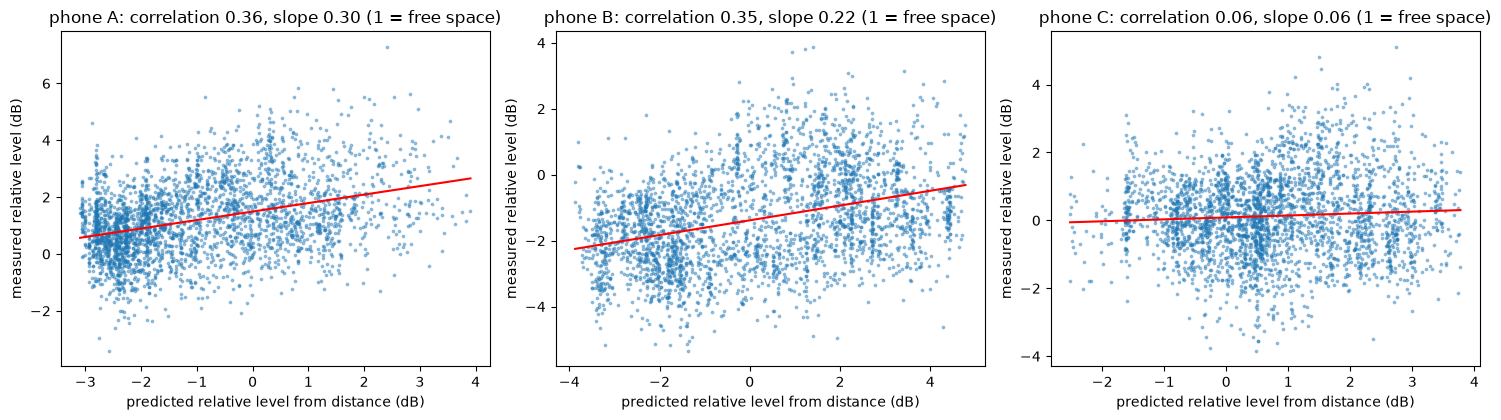

In [20]:
dist = np.sqrt(((truth[:, None, :] - P[None]) ** 2).sum(-1) + MOUTH_Z ** 2)      # (windows, 3), meters
pred_rel = -20 * np.log10(dist); pred_rel -= pred_rel.mean(1, keepdims=True)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for i, name in enumerate("ABC"):
    ax[i].scatter(pred_rel[:, i], X_broad[:, i], s=3, alpha=0.4)
    slope, icpt = np.polyfit(pred_rel[:, i], X_broad[:, i], 1)
    r = np.corrcoef(pred_rel[:, i], X_broad[:, i])[0, 1]
    ax[i].plot(np.sort(pred_rel[:, i]), slope * np.sort(pred_rel[:, i]) + icpt, "r")
    ax[i].set_title(f"phone {name}: correlation {r:.2f}, slope {slope:.2f} (1 = free space)")
    print(f"phone {name}: correlation {r:.2f}, slope {slope:.2f}")
    ax[i].set_xlabel("predicted relative level from distance (dB)"); ax[i].set_ylabel("measured relative level (dB)")
plt.tight_layout()

## The models: three small ones, a ladder
Each step adds flexibility, so a gain can be traced to a cause.
1. **Ridge regression**: a linear map from features to (x, y). A few dozen weights, one regularisation strength. Tests whether the relation is even roughly linear.
2. **k-nearest-neighbours**: for a window, find the k most similar training windows (closer ones weigh more) and average their positions. No training, and natural for a fingerprint-style signal.
3. **Small MLP**: input -> 64 -> 64 -> 2 (x, y in meters), ReLU, dropout 0.1, weight decay, Adam, squared error. About 6,000 parameters at 24 inputs. The number of training epochs is chosen on the validation set and five seeds are averaged.

Left out for now: gradient-boosted trees (likely to behave like kNN on this little data), a classifier over floor cells (only matters if one input implied several likely positions), and a CNN on spectrograms (added afterwards as section 4b, since these simple models showed there is signal).

All three models are run on both inputs (broadband: 3 numbers; 8 bands: 24 numbers), six combinations, plus the mean-position baseline.

## How it is scored: one fixed split
* **Train / validation:** sessions 1 and 2 only. Within **each** of them, the first 80% of the windows (in time order) are for training and the last 20% for validation. Training windows within 2 s of the boundary are dropped: windows overlap by half, so without the gap a validation window would share audio with a training window.
* **Test:** session 3 only, used once, after everything is chosen. It never takes part in a choice (ridge strength, k, number of MLP epochs, standardisation).
* **Choosing settings:** each setting is picked by the lowest mean error on the validation set (models trained on the 80% parts). Then the model is **retrained from scratch on all of sessions 1 and 2** (train + validation) with that setting, and predicts session 3. For the MLP the epoch count found on the 80% part is reused.
* **Which model is the headline:** decided before looking at the test numbers: the combination with the lowest **validation** error. All six test results are reported as they are; none is picked by its test score.
* Same error numbers as before (median, mean, 90th percentile, in cm), against the mean-position baseline (mean of sessions 1 and 2 as the answer).

### Why this design, and what it cannot tell us (discussion, kept for the write-up)
* **Validation is easier than the test, by construction.** The last 20% of a session revisits places seen in its first 80%, and sessions 1 and 2 overlap in where the speaker walked. So validation measures *familiar* areas. Session 3 covers areas the other two barely visited, so the test measures *new* areas. The gap between the two numbers is itself informative: it shows how much is lost when the speaker is somewhere the model has not heard before. The side effect is that validation favours settings that fit familiar places tightly (small k, long training), which are not necessarily best for new places.
* **One test session is one sample.** Its 826 windows are not independent: neighbours overlap and are seconds apart, and everything a session shares (route, evening, speech material) is a single draw. The window count says how stable the score is on this session, not how much it would change on another route. Treat differences of a few cm between models as noise.
* **Session 3 was looked at before.** An earlier version of this section (leave-one-session-out) already scored models on session 3, so it is not perfectly untouched. The design (features, models, settings grid) is the same as then and nothing here was adjusted after seeing session 3.
* A cleaner test would be a new session, recorded after the design is frozen, ideally on a different route.

In [21]:
import torch.nn as nn, torch.nn.functional as F

def std_fit(Xa, Xb):
    mu, sd = Xa.mean(0), Xa.std(0) + 1e-6
    return (Xa - mu) / sd, (Xb - mu) / sd

def ridge_fn(Xa, Ya, Xb, alpha, keep=None):
    mu, sd = Xa.mean(0), Xa.std(0) + 1e-6
    Xa, Xb = std_fit(Xa, Xb); ym = Ya.mean(0)
    W = np.linalg.solve(Xa.T @ Xa + alpha * np.eye(Xa.shape[1]), Xa.T @ (Ya - ym))
    if keep is not None: keep.append(dict(W=W, mu=mu, sd=sd, ym=ym))
    return Xb @ W + ym

def knn_fn(Xa, Ya, Xb, k, keep=None):
    mu, sd = Xa.mean(0), Xa.std(0) + 1e-6
    Xa, Xb = std_fit(Xa, Xb)
    if keep is not None: keep.append(dict(Xa=Xa.astype(np.float32), Ya=Ya, mu=mu, sd=sd, k=k))
    d = torch.cdist(torch.tensor(Xb, dtype=torch.float32), torch.tensor(Xa, dtype=torch.float32))
    dv, ix = d.topk(k, largest=False)
    w = 1 / (dv + 1e-3); w = (w / w.sum(1, keepdim=True)).numpy()
    return (Ya[ix.numpy()] * w[..., None]).sum(1)

def make_mlp(d):
    return nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 2))

def mlp_fit(Xa, Ya, Xb, epochs, seed, Yb=None, keep=None):
    # train on (Xa, Ya); returns predictions for Xb after `epochs`, and (if Yb given) the mean error on Xb after every epoch
    mu, sd = Xa.mean(0), Xa.std(0) + 1e-6
    Xa, Xb = std_fit(Xa, Xb); ym = Ya.mean(0)
    xa, ya = torch.tensor(Xa, dtype=torch.float32), torch.tensor(Ya - ym, dtype=torch.float32)
    xb = torch.tensor(Xb, dtype=torch.float32)
    torch.manual_seed(seed)
    net = make_mlp(Xa.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=3e-3, weight_decay=1e-3)
    curve = []
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(xa))
        for s in range(0, len(xa), 128):
            b = perm[s:s + 128]; opt.zero_grad(); F.mse_loss(net(xa[b]), ya[b]).backward(); opt.step()
        if Yb is not None:
            net.eval()
            with torch.no_grad():
                curve.append(float(np.linalg.norm(net(xb).numpy() + ym - Yb, axis=1).mean()))
    net.eval()
    if keep is not None: keep.append(dict(state={k: v.detach().clone() for k, v in net.state_dict().items()}, mu=mu, sd=sd, ym=ym))
    with torch.no_grad():
        return net(xb).numpy() + ym, curve

In [22]:
GAP = 2.0                                               # s: training windows this close to the validation boundary are dropped
tr_idx, va_idx = [], []
for n in (1, 2):
    ix = np.where(sess == n)[0]                         # windows of the session, in time order
    cut = int(round(0.8 * len(ix)))
    t_b = t_centre[ix[cut]]
    va_idx += list(ix[cut:])
    tr_idx += [i for i in ix[:cut] if t_centre[i] <= t_b - GAP]
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)
fit_idx = np.where(sess != 3)[0]                        # sessions 1 and 2, all windows: used for the final fit
te_idx = np.where(sess == 3)[0]
print(f"train {len(tr_idx)}  validation {len(va_idx)}  (sessions 1+2)   final fit {len(fit_idx)}   test {len(te_idx)} (session 3)")

def errs(pred, idx):
    return np.linalg.norm(pred - Y[idx], axis=1) * 100

def stats(e):
    return f"median {np.median(e):5.1f}  mean {e.mean():5.1f}  p90 {np.percentile(e, 90):5.1f}"

results = {}                                            # (input, method) -> dict(setting, val error array, test error array, test prediction)
base_val, base_te = errs(Y[tr_idx].mean(0), va_idx), errs(Y[fit_idx].mean(0), te_idx)
print(f"{'mean position (baseline)':<34} val: {stats(base_val)}   |   test: {stats(base_te)}")

def best_setting(fn, grid, X):
    sc = {g: errs(fn(X[tr_idx], Y[tr_idx], X[va_idx], g), va_idx).mean() for g in grid}
    return min(sc, key=sc.get)

for in_name, X in (("broadband", X_broad), ("8-band", X_band)):
    for method in ("ridge", "knn", "mlp"):
        if method in ("ridge", "knn"):
            fn, grid = (ridge_fn, [0.1, 1, 10, 100, 1000, 10000, 100000]) if method == "ridge" else (knn_fn, [5, 10, 20, 40, 80, 160, 320])
            g = best_setting(fn, grid, X)
            kp = []
            pv, pt = fn(X[tr_idx], Y[tr_idx], X[va_idx], g), fn(X[fit_idx], Y[fit_idx], X[te_idx], g, keep=kp)
            setting = f"{'alpha' if method == 'ridge' else 'k'}={g}"
        else:
            curve = np.mean([mlp_fit(X[tr_idx], Y[tr_idx], X[va_idx], 100, sd, Y[va_idx])[1] for sd in (0, 1)], axis=0)
            g = int(np.argmin(np.convolve(curve, np.ones(5) / 5, "valid"))) + 3
            pv = np.mean([mlp_fit(X[tr_idx], Y[tr_idx], X[va_idx], g, sd)[0] for sd in range(5)], axis=0)
            kp = []
            pt = np.mean([mlp_fit(X[fit_idx], Y[fit_idx], X[te_idx], g, sd, keep=kp)[0] for sd in range(5)], axis=0)
            setting = f"epochs={g}"
        results[(in_name, method)] = dict(setting=setting, val=errs(pv, va_idx), test=errs(pt, te_idx), pred=pt, keep=kp)
        r = results[(in_name, method)]
        print(f"{in_name + ', ' + method + ' (' + setting + ')':<34} val: {stats(r['val'])}   |   test: {stats(r['test'])}")

headline = min(results, key=lambda k: results[k]["val"].mean())
print("\nheadline model, chosen by validation error:", headline, "->", results[headline]["setting"])

train 1704  validation 427  (sessions 1+2)   final fit 2137   test 826 (session 3)
mean position (baseline)           val: median  72.3  mean  71.4  p90 104.4   |   test: median  97.7  mean  98.3  p90 145.8
broadband, ridge (alpha=1000)      val: median  69.6  mean  68.6  p90 101.9   |   test: median  94.9  mean  93.9  p90 137.4
broadband, knn (k=320)             val: median  69.7  mean  68.2  p90 105.3   |   test: median  92.6  mean  92.5  p90 139.0


broadband, mlp (epochs=84)         val: median  68.7  mean  67.9  p90 102.5   |   test: median  93.2  mean  92.5  p90 138.1
8-band, ridge (alpha=1000)         val: median  50.2  mean  55.7  p90  91.8   |   test: median  77.3  mean  79.6  p90 130.3
8-band, knn (k=10)                 val: median  39.1  mean  48.0  p90  88.2   |   test: median  65.0  mean  70.8  p90 127.5


8-band, mlp (epochs=15)            val: median  37.9  mean  45.0  p90  77.8   |   test: median  62.1  mean  67.9  p90 122.8

headline model, chosen by validation error: ('8-band', 'mlp') -> epochs=15


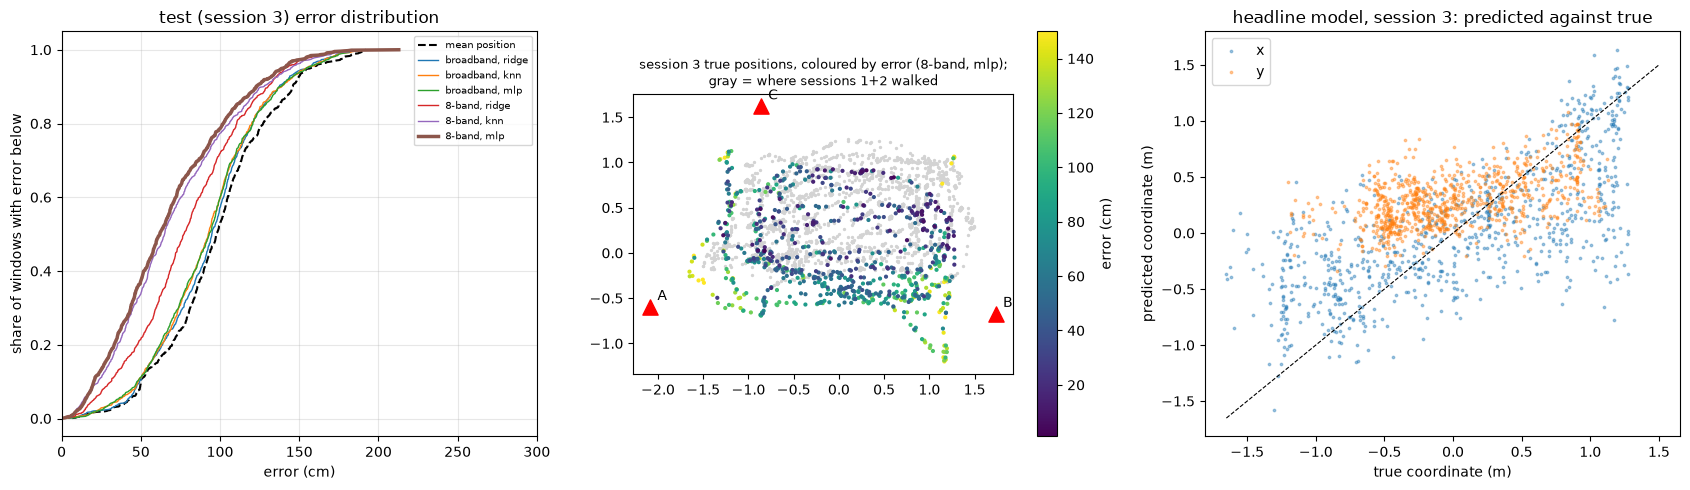

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].plot(np.sort(base_te), np.arange(1, len(base_te) + 1) / len(base_te), "k--", label="mean position")
for k, r in results.items():
    ax[0].plot(np.sort(r["test"]), np.arange(1, len(r["test"]) + 1) / len(r["test"]), lw=2.5 if k == headline else 1, label=f"{k[0]}, {k[1]}")
ax[0].set_xlim(0, 300); ax[0].set_xlabel("error (cm)"); ax[0].set_ylabel("share of windows with error below"); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3)
ax[0].set_title("test (session 3) error distribution")
r = results[headline]; te_truth = Y[te_idx]; order = np.argsort(-r["test"])
sc = ax[1].scatter(*te_truth[order].T, s=4, c=r["test"][order], cmap="viridis", vmax=150)
ax[1].scatter(*Y[fit_idx].T, s=2, c="lightgray", zorder=0)
for p, (px, py) in ds.phones.items():
    ax[1].scatter(px, py, marker="^", s=120, c="r"); ax[1].annotate(p, (px, py), xytext=(5, 5), textcoords="offset points")
ax[1].set_aspect("equal"); plt.colorbar(sc, ax=ax[1], label="error (cm)")
ax[1].set_title(f"session 3 true positions, coloured by error ({headline[0]}, {headline[1]});\ngray = where sessions 1+2 walked", fontsize=9)
ax[2].scatter(te_truth[:, 0], r["pred"][:, 0], s=3, alpha=0.4, label="x"); ax[2].scatter(te_truth[:, 1], r["pred"][:, 1], s=3, alpha=0.4, label="y")
lim = [Y.min(), Y.max()]; ax[2].plot(lim, lim, "k--", lw=0.8)
ax[2].set_xlabel("true coordinate (m)"); ax[2].set_ylabel("predicted coordinate (m)"); ax[2].legend(); ax[2].set_title("headline model, session 3: predicted against true")
plt.tight_layout()

## Part 4 results (fixed split: train/validate on sessions 1+2, test on session 3)

Median error in cm, mean-position baseline first. "Validation" is the last 20% of sessions 1 and 2 (familiar areas; models trained on the first 80%). "Test" is session 3 (models retrained on all of sessions 1 and 2).

| input | model | setting (from validation) | validation median | **test median** | test mean | test 90th pct |
|---|---|---|---|---|---|---|
| (baseline) mean position | none | | 72 | **98** | 98 | 146 |
| broadband levels (3 numbers) | ridge | alpha=1000 | 70 | 95 | 94 | 137 |
| | kNN | k=320 | 70 | 93 | 93 | 139 |
| | MLP | 84 epochs | 69 | 93 | 93 | 138 |
| 8-band levels (24 numbers) | ridge | alpha=1000 | 50 | 77 | 80 | 130 |
| | kNN | k=10 | 39 | 65 | 71 | 128 |
| | **MLP (headline, lowest validation error)** | 15 epochs | **38** | **62** | 68 | 123 |

**What it means**
* **The 8-band model beats the baseline on new areas: 62 cm against 98 cm** (about a third lower) on a session it never saw, which also covers places sessions 1 and 2 barely visited. On the familiar validation areas the improvement is larger: 38 cm against 72 cm (about half).
* **Validation to test: 38 -> 62 cm.** That 24 cm gap is the price of going to unfamiliar places. It is the number to quote when asking how far the fingerprint generalises within this room.
* **Broadband loudness carries almost nothing**, as before: its validation and test errors sit within a few cm of the baseline, and kNN wanted the smoothest setting on its grid (k=320), which is nearly the mean prediction. The signal is in the frequency balance, not the plain level.
* **Linear < kNN <= MLP** on 8 bands (77, 65, 62 cm). The MLP and kNN differ by 3 cm, which is within noise for one test session, so do not read it as one being better; the MLP was the headline only because its validation error was lowest, as decided in advance. The MLP's best epoch count was small (15), meaning it starts to memorise the training sessions quickly.
* **Predictions are pulled toward the middle** (the right panel is flatter than the diagonal; y is predicted between about 0 and 1 m while the truth spans about -1.2 to 1.2 m). A model that learns a fingerprint cannot answer outside the range it has seen. Errors are largest along the lower edge and the right side of session 3's route, away from where sessions 1 and 2 walked.

**Caveats**
* This is an acoustic fingerprint of this room in this evening's conditions, not evidence that the physics works.
* One test session is one sample (see the discussion above); differences of a few cm between models are noise.
* Session 3 was seen in an earlier leave-one-session-out version of this section (same design, same 62 cm for this split), so it is not perfectly untouched.
* We have not checked what the model relies on: facing direction or speech content could also change along the route.

**Possible next steps**
* Ablations: which bands matter, cross-spectral magnitudes between phones, longer windows (2-4 s) now that timing is not involved.
* (A CNN on log-mel spectrograms of the three channels is section 4b below; the raw-audio model is Part 5.)
* A new session on a different route, recorded after the design is frozen, as a clean test.

### 4b. A small CNN on log-mel spectrograms (still grey-box)
The 8-band model compresses each phone's window to 8 numbers by hand. Here we keep more of the picture and let a small network decide what to extract: for each phone, a **log-mel spectrogram** (32 mel bands from 300 to 4000 Hz, 101 time frames of 32 ms with a 10 ms hop), the three phones stacked as the three channels of one image.

**Why this is still grey-box.** The spectral transform (STFT, mel bands, dB) and the **relative-to-phone-average** step (as before: subtract the mean over the three phones in every bin and frame, so how loudly you speak cancels) are hand-built. Phase is thrown away, so, as before, nothing depends on timing between phones. The network only learns which patterns in the spectrograms matter. The fully black-box version (raw samples in) is Part 5.

**Keeping it small (documented choices).** There are only about 1,700 training windows (2,100 for the final fit) and, being half-overlapping, about half as many independent ones. A large network would memorise them, so:
* Three 3x3 convolution blocks (3 -> 8 -> 16 -> 32 channels), each with batch norm, ReLU and 2x2 max pooling, then an average over time, then one linear layer: **about 6,400 parameters**, the same size as the 8-band MLP (6,000).
* **Averaging over time before the output.** The label is one position per window, and what the speaker says changes every moment, so only the pattern that persists through the window should matter; this also removes a large source of capacity.
* **Dropout 0.3** before the output layer, **weight decay**, and the number of **training epochs chosen on the validation set** (early stopping), as for the MLP.
* Same protocol as the rest of Part 4: train on the first 80% of sessions 1 and 2, choose the epoch count on the last 20%, retrain on all of sessions 1 and 2, test once on session 3 (three seeds averaged).

In [24]:
import torch.nn.functional as F
N_FFT, HOP, N_MELS = 512, 160, 32

def mel_filters():
    mel = lambda f: 2595 * np.log10(1 + f / 700); imel = lambda m: 700 * (10 ** (m / 2595) - 1)
    edges = imel(np.linspace(mel(BAND[0]), mel(BAND[1]), N_MELS + 2))
    fr = np.fft.rfftfreq(N_FFT, 1 / fs); fb = np.zeros((N_MELS, len(fr)), np.float32)
    for m in range(N_MELS):
        lo, mid, hi = edges[m:m + 3]
        fb[m] = np.clip(np.minimum((fr - lo) / (mid - lo), (hi - fr) / (hi - mid)), 0, None)
    return torch.tensor(fb)

FB = mel_filters(); STFT_WIN = torch.hann_window(N_FFT)
def logmel(audio):
    # (B, 3, W) -> (B, 3, 32, frames) in dB, relative to the average over the three phones
    B = audio.shape[0]
    p = torch.stft(audio.reshape(B * 3, -1), N_FFT, HOP, window=STFT_WIN, return_complex=True).abs() ** 2
    s = 10 * torch.log10(torch.einsum("mf,bft->bmt", FB, p) + 1e-10).reshape(B, 3, N_MELS, -1)
    return (s - s.mean(1, keepdim=True)).numpy()

S = np.concatenate([logmel(b["audio"]) for b in DataLoader(ds, batch_size=64, shuffle=False)])
print("log-mel input:", S.shape, f"({S[0].size} numbers per window)")

def make_spec_cnn():
    def blk(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(3, 8), *blk(8, 16), *blk(16, 32), nn.AdaptiveAvgPool2d((4, 1)), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 2))

def train_net(make_net, Xa, Ya, Xb, epochs, seed, Yb=None, raw=False, lr=2e-3, keep=None):
    # trains a fresh network on (Xa, Ya); returns predictions for Xb after `epochs` and, if Yb is given, the validation error after every epoch
    ym = Ya.mean(0)
    if raw: sd = float(Xa.std()); norm = lambda x: x / sd
    else:
        mu = torch.tensor(Xa.mean((0, 3), keepdims=True)); sdv = torch.tensor(Xa.std((0, 3), keepdims=True) + 1e-6); norm = lambda x: (x - mu) / sdv
    xa, xb = torch.tensor(Xa), torch.tensor(Xb); ya = torch.tensor(Ya - ym, dtype=torch.float32)
    torch.manual_seed(seed); net = make_net()
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-3)
    def predict(x):
        net.eval()
        with torch.no_grad():
            return torch.cat([net(norm(x[i:i + 256])) for i in range(0, len(x), 256)]).numpy() + ym
    curve = []
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(xa))
        for s0 in range(0, len(xa), 64):
            b = perm[s0:s0 + 64]
            if len(b) < 2: continue
            xbatch = xa[b]
            if raw: xbatch = xbatch * (10 ** (torch.empty(len(b), 1, 1).uniform_(-6, 6) / 20))     # same random gain on all three phones
            opt.zero_grad(); F.mse_loss(net(norm(xbatch)), ya[b]).backward(); opt.step()
        if Yb is not None:
            curve.append(float(np.linalg.norm(predict(xb) - Yb, axis=1).mean()))
    if keep is not None: keep.append(dict(state={k: v.detach().clone() for k, v in net.state_dict().items()}, ym=ym, norm=(sd,) if raw else (mu.numpy(), sdv.numpy())))
    return predict(xb), curve

def run_net(name, make_net, X, raw, max_epochs, final_seeds=3):
    print(f"{name}: {sum(p.numel() for p in make_net().parameters()):,} parameters, {X[0].size:,} numbers per window, {len(tr_idx):,} training windows")
    curve = np.mean([train_net(make_net, X[tr_idx], Y[tr_idx], X[va_idx], max_epochs, sd, Y[va_idx], raw)[1] for sd in (0, 1)], axis=0)
    g = int(np.argmin(np.convolve(curve, np.ones(3) / 3, "valid"))) + 2
    pv = np.mean([train_net(make_net, X[tr_idx], Y[tr_idx], X[va_idx], g, sd, None, raw)[0] for sd in range(final_seeds)], axis=0)
    kp = []
    pt = np.mean([train_net(make_net, X[fit_idx], Y[fit_idx], X[te_idx], g, sd, None, raw, keep=kp)[0] for sd in range(final_seeds)], axis=0)
    r = dict(setting=f"epochs={g}", val=errs(pv, va_idx), test=errs(pt, te_idx), pred=pt, curve=curve, keep=kp)
    print(f"{name} ({r['setting']})".ljust(34), f"val: {stats(r['val'])}   |   test: {stats(r['test'])}")
    return r

res_cnn = run_net("log-mel CNN", make_spec_cnn, S, raw=False, max_epochs=60)

log-mel input: (2963, 3, 32, 101) (9696 numbers per window)
log-mel CNN: 6,402 parameters, 9,696 numbers per window, 1,704 training windows


log-mel CNN (epochs=35)            val: median  35.1  mean  40.4  p90  64.2   |   test: median  60.3  mean  64.1  p90 114.2


**Results of 4b** (median error in cm; same split and rules as above)

| model | parameters | numbers per window | setting | validation | **test (session 3)** | test mean | test 90th pct |
|---|---|---|---|---|---|---|---|
| 8-band MLP (for reference) | 6,000 | 24 | 15 epochs | 38 | **62** | 68 | 123 |
| **log-mel CNN** | 6,402 | 9,696 | 35 epochs | **35** | **60** | 64 | 114 |

* The CNN is **about as good as the 8-band MLP**: 60 against 62 cm on the test, 35 against 38 cm on validation. The gap is within the noise of one test session, so the honest reading is "no measurable gain": letting the network pick its own spectral features from 9,696 numbers did not extract more position information than the 8 hand-picked band levels. The tail (90th percentile 114 against 123 cm) is a bit better, which may be real or not.
* Under the rule fixed beforehand (headline = lowest validation error over all models), the CNN is now the headline of the grey-box part, with the MLP a close second. Do not read the 2 cm as a win for the CNN.
* The learned features did not buy more, which suggests the usable information in these recordings is largely the frequency balance between the phones that the 8 bands already capture, at least at this amount of data.

# Part 5: black-box: raw audio into a network

The far end of the comparison: nothing is computed by hand. The input is the band-passed, 16 kHz waveform of the three phones, **48,000 numbers per window**, against about 1,700 training windows. A network of the usual size on this would simply memorise the training sessions. So even here the network is deliberately shrunk, and the point of this part is to see what a black-box model can do **when it is given a fair chance**, not to show that an oversized one overfits.

**Keeping it small (documented choices).**
* **A strided first layer.** The first convolution uses 80-sample (5 ms) kernels with stride 16, over all three phones at once: a learned filterbank that also cuts the time axis 16 times (16,000 -> 996). Later convolutions use stride 4 (-> 247 -> 60 steps).
* **Averaging over time at the end** (global average pool, leaving 32 numbers per window), because the label is one position per window; this behaves like a learned version of the band energies of the grey-box model.
* **Dropout** 0.2 inside and 0.5 before the output, batch norm, **weight decay**, and the number of **training epochs chosen on the validation set** (early stopping).
* **Random gain augmentation.** Every training window is multiplied by a random gain between -6 and +6 dB, the same on all three phones. How loudly the speaker talks therefore cannot be used; only the levels *between* phones can. (The grey-box inputs remove this by subtracting the phone average.)
* About **11,000 parameters**: the same order as the other models, although the input is 2,000 times larger than the 24 band numbers.
* Same protocol as before: train on the first 80% of sessions 1 and 2, choose the epoch count on the last 20%, retrain on all of sessions 1 and 2, test once on session 3 (three seeds averaged).

**What this model can and cannot do.** It sees the raw samples of all three phones together, so in principle it can use the timing between phones that GCC-PHAT failed to find; but the strides, the pooling and the amount of data limit how precisely it could learn that. **Prediction, written before running:** it will not beat the 8-band models, and will land between them and the mean-position baseline. A result at the baseline would mean a black-box model cannot extract the signal from this little data; a result near the 8-band model would mean it found the same cue by itself.

In [25]:
X_raw = np.concatenate([b["audio"].numpy() for b in DataLoader(ds, batch_size=64, shuffle=False)])       # (windows, 3, 16000)

def make_raw_cnn():
    def blk(i, o, k, s, drop): return [nn.Conv1d(i, o, k, stride=s), nn.BatchNorm1d(o), nn.ReLU()] + ([nn.Dropout(drop)] if drop else [])
    return nn.Sequential(*blk(3, 16, 80, 16, 0), *blk(16, 16, 9, 4, 0.2), *blk(16, 32, 9, 4, 0.2),
                         nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(32, 2))

res_raw = run_net("raw-audio CNN", make_raw_cnn, X_raw, raw=True, max_epochs=40)

raw-audio CNN: 11,010 parameters, 48,000 numbers per window, 1,704 training windows


raw-audio CNN (epochs=26)          val: median  55.7  mean  57.0  p90  97.1   |   test: median  80.2  mean  81.7  p90 135.6


**Results of Part 5** (median error in cm; same split and rules)

| model | parameters | numbers per window | setting | validation | **test (session 3)** | test mean | test 90th pct |
|---|---|---|---|---|---|---|---|
| mean position (baseline) | | | | 72 | **98** | 98 | 146 |
| **raw-audio CNN** | 11,010 | 48,000 | 26 epochs | 56 | **80** | 82 | 136 |
| 8-band MLP | 6,000 | 24 | 15 epochs | 38 | **62** | 68 | 123 |
| log-mel CNN | 6,402 | 9,696 | 35 epochs | 35 | **60** | 64 | 114 |

* **The prediction held:** the black-box model lands between the baseline and the grey-box models. Even with only about 1,700 training windows and 48,000 inputs, a deliberately small network with dropout, weight decay, gain augmentation and early stopping learns something real: 80 cm against 98 cm on the new session, and 56 against 72 cm on the familiar areas. It is, however, about 18-20 cm behind the models that were handed the spectral transform.
* The comparison therefore reads: **the more is built in by hand, the better it does at this data size** (log-mel CNN ~ 8-band MLP < raw-audio CNN < baseline), with timing (GCC-PHAT) the failure case.
* We do not know what the raw-audio network used. Because of the random gain it cannot use absolute loudness; the likeliest cue is the same between-phone frequency balance, found less efficiently, but it could also exploit some of the timing structure that GCC-PHAT could not. Not tested.
* This is **not a ceiling for black-box models**: the network was kept small on purpose because of the data size. With much more recorded audio (or other rooms and speakers) a larger one could close the gap, or not; we cannot say.

model                       validation median  validation mean  test median  test mean  test p90
mean position (baseline)                 72.3             71.4         97.7       98.3     145.8
log-mel CNN                              35.1             40.4         60.3       64.1     114.2
8-band, mlp                              37.9             45.0         62.1       67.9     122.8
8-band, knn                              39.1             48.0         65.0       70.8     127.5
8-band, ridge                            50.2             55.7         77.3       79.6     130.3
raw-audio CNN                            55.7             57.0         80.2       81.7     135.6
broadband, mlp                           68.7             67.9         93.2       92.5     138.1
broadband, knn                           69.7             68.2         92.6       92.5     139.0
broadband, ridge                         69.6             68.6         94.9       93.9     137.4

lowest validation error (the 

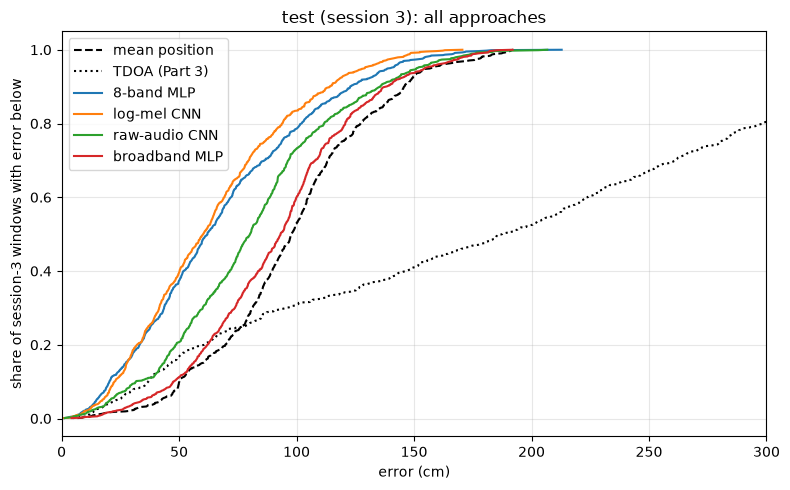

In [26]:
all_models = {f"{k[0]}, {k[1]}": r for k, r in results.items()}
all_models["log-mel CNN"], all_models["raw-audio CNN"] = res_cnn, res_raw
print(f"{'model':<26}{'validation median':>19}{'validation mean':>17}{'test median':>13}{'test mean':>11}{'test p90':>10}")
print(f"{'mean position (baseline)':<26}{np.median(base_val):19.1f}{base_val.mean():17.1f}{np.median(base_te):13.1f}{base_te.mean():11.1f}{np.percentile(base_te, 90):10.1f}")
for k, r in sorted(all_models.items(), key=lambda kv: kv[1]["val"].mean()):
    print(f"{k:<26}{np.median(r['val']):19.1f}{r['val'].mean():17.1f}{np.median(r['test']):13.1f}{r['test'].mean():11.1f}{np.percentile(r['test'], 90):10.1f}")
print("\nlowest validation error (the rule for the headline):", min(all_models, key=lambda k: all_models[k]["val"].mean()))

plt.figure(figsize=(8, 5))
for name, e, st in (("mean position", base_te, "k--"), ("TDOA (Part 3)", err_tdoa, "k:"), ("8-band MLP", results[("8-band", "mlp")]["test"], "-"),
                    ("log-mel CNN", res_cnn["test"], "-"), ("raw-audio CNN", res_raw["test"], "-"), ("broadband MLP", results[("broadband", "mlp")]["test"], "-")):
    plt.plot(np.sort(e[:len(e)] if name != "TDOA (Part 3)" else e[sess == 3]), np.arange(1, (len(e) if name != "TDOA (Part 3)" else (sess == 3).sum()) + 1) / (len(e) if name != "TDOA (Part 3)" else (sess == 3).sum()), st, label=name)
plt.xlim(0, 300); plt.xlabel("error (cm)"); plt.ylabel("share of session-3 windows with error below"); plt.grid(alpha=0.3); plt.legend(); plt.title("test (session 3): all approaches")
plt.tight_layout()

## Saving the trained models
The final models (the ones fitted on all of sessions 1 and 2 and scored on session 3) are saved to `trained_models/`, one file per input and model, so the 62 / 60 / 80 cm results can be reloaded without retraining. Each file holds, for every random seed that was averaged, the network weights (or the ridge weights, or the kNN reference windows), the standardisation numbers used with them, the target mean, and the chosen setting. The network *architectures* are the functions `make_mlp`, `make_spec_cnn` and `make_raw_cnn` in this notebook; the features are `band_levels` and `logmel`. Files are written with `torch.save` (pickle; load with `weights_only=False`). The cell reloads two of them and checks that they reproduce the predictions above.

In [27]:
import json
SAVE_DIR = Path("trained_models"); SAVE_DIR.mkdir(exist_ok=True)
everything = {f"{k[0]}_{k[1]}": (k[0], k[1], r) for k, r in results.items()}
everything["logmel_cnn"], everything["raw_cnn"] = ("log-mel spectrogram", "cnn", res_cnn), ("raw audio", "cnn", res_raw)
summary = {}
for name, (inp, method, r) in everything.items():
    torch.save(dict(name=name, input=inp, method=method, setting=r["setting"], members=r["keep"],
                    val_median_cm=float(np.median(r["val"])), test_median_cm=float(np.median(r["test"]))), SAVE_DIR / f"{name}.pt")
    summary[name] = dict(input=inp, method=method, setting=r["setting"], seeds=len(r["keep"]) if method in ("mlp", "cnn") else 1,
                         val_median_cm=round(float(np.median(r["val"])), 1), test_median_cm=round(float(np.median(r["test"])), 1),
                         file=f"{name}.pt", size_kb=round((SAVE_DIR / f"{name}.pt").stat().st_size / 1024))
json.dump(dict(trained_on="sessions 1 and 2 (all windows)", tested_on="session 3", window_s=WINDOW_LEN, step_s=STEP_LEN, sample_rate=fs, band_hz=list(BAND),
               band_edges_8=BANDS.tolist(), n_mels=N_MELS, models=summary), open(SAVE_DIR / "summary.json", "w"), indent=1)
print(f"{'file':<28}{'setting':<14}{'seeds':>6}{'size':>9}")
for name, s_ in summary.items():
    print(f"{s_['file']:<28}{s_['setting']:<14}{s_['seeds']:>6}{s_['size_kb']:>7} kB")

# reload two of them and check that they reproduce this notebook's session-3 predictions
def predict_mlp(members, X):
    out = []
    for m in members:
        net = make_mlp(X.shape[1]); net.load_state_dict(m["state"]); net.eval()
        with torch.no_grad(): out.append(net(torch.tensor((X - m["mu"]) / m["sd"], dtype=torch.float32)).numpy() + m["ym"])
    return np.mean(out, axis=0)

def predict_cnn(members, make_net, X, raw):
    out = []
    for m in members:
        net = make_net(); net.load_state_dict(m["state"]); net.eval()
        xx = torch.tensor(X)
        xx = xx / m["norm"][0] if raw else (xx - torch.tensor(m["norm"][0])) / torch.tensor(m["norm"][1])
        with torch.no_grad(): out.append(torch.cat([net(xx[i:i + 256]) for i in range(0, len(xx), 256)]).numpy() + m["ym"])
    return np.mean(out, axis=0)

ck = torch.load(SAVE_DIR / "8-band_mlp.pt", weights_only=False)
p1 = predict_mlp(ck["members"], X_band[te_idx]); print("reloaded 8-band MLP: max difference from the notebook's predictions", np.abs(p1 - results[("8-band", "mlp")]["pred"]).max().round(6), "m")
ck = torch.load(SAVE_DIR / "logmel_cnn.pt", weights_only=False)
p2 = predict_cnn(ck["members"], make_spec_cnn, S[te_idx], raw=False); print("reloaded log-mel CNN: max difference from the notebook's predictions", np.abs(p2 - res_cnn["pred"]).max().round(6), "m")

file                        setting        seeds     size
broadband_ridge.pt          alpha=1000         1      2 kB
broadband_knn.pt            k=320              1     91 kB
broadband_mlp.pt            epochs=84          5    100 kB
8-band_ridge.pt             alpha=1000         1      3 kB
8-band_knn.pt               k=10               1    355 kB
8-band_mlp.pt               epochs=15          5    127 kB
logmel_cnn.pt               epochs=35          3    100 kB
raw_cnn.pt                  epochs=26          3    150 kB
reloaded 8-band MLP: max difference from the notebook's predictions 0.0 m


reloaded log-mel CNN: max difference from the notebook's predictions 0.0 m


## How good is it, really? (session 3)
A median error of 60 cm only means something against reference points. This section puts the models next to three:
* **Mean position**: the answer that ignores the audio (the baseline above).
* **Blind guess**: a random position drawn from where sessions 1 and 2 walked, i.e. someone who knows the route but hears nothing. Averaged over 200 draws.
* **The size of the area** that was walked: the bounding box of positions in sessions 1+2, and a **3x3 zone accuracy** (the box is cut into nine equal cells; how often is the predicted cell the true one).

It also reports **R-squared** per axis (1 = perfect, 0 = no better than always answering the mean of session 3) and the error after **smoothing the predicted track** with a 5-window running median (2.5 s). Smoothing is allowed in a tracking use because a person moves about 0.4 m/s, so consecutive windows are close together, and a single window's guess can be wrong while its neighbours are right.

In [28]:
models3 = {"8-band MLP": results[("8-band", "mlp")], "log-mel CNN": res_cnn, "raw-audio CNN": res_raw}
te_truth, te_t = Y[te_idx], t_centre[te_idx]
span = Y[fit_idx].max(0) - Y[fit_idx].min(0)
print(f"walked area in sessions 1+2: x {Y[fit_idx][:, 0].min():.2f} to {Y[fit_idx][:, 0].max():.2f} m, y {Y[fit_idx][:, 1].min():.2f} to {Y[fit_idx][:, 1].max():.2f} m  ({span[0]:.1f} x {span[1]:.1f} m)\n")

def smooth(p, k=5):
    return np.array([np.median(p[max(0, i - k // 2):i + k // 2 + 1], axis=0) for i in range(len(p))])
def r2(p, t):
    return 1 - ((p - t) ** 2).sum(0) / ((t - t.mean(0)) ** 2).sum(0)
lo, hi = Y[fit_idx].min(0), Y[fit_idx].max(0)
def zone(p):
    ix = np.clip(((p - lo) / (hi - lo) * 3).astype(int), 0, 2)
    return ix[:, 0] * 3 + ix[:, 1]
rng = np.random.default_rng(0)
blind = [Y[fit_idx][rng.integers(0, len(fit_idx), len(te_idx))] for _ in range(200)]
rows = {"blind guess (route known, no audio)": None, "mean position": np.tile(Y[fit_idx].mean(0), (len(te_idx), 1))}
rows.update({k: r["pred"] for k, r in models3.items()})
print(f"{'':<38}{'median':>7}{'mean':>6}{'<50cm':>7}{'<100cm':>8}{'R2 x':>7}{'R2 y':>7}{'3x3 zone':>10}{'median, smoothed':>18}")
for name, p in rows.items():
    if p is None:
        e = np.mean([np.median(np.linalg.norm(b - te_truth, axis=1)) * 100 for b in blind])
        e_mean = np.mean([np.linalg.norm(b - te_truth, axis=1).mean() * 100 for b in blind])
        w50 = np.mean([(np.linalg.norm(b - te_truth, axis=1) < 0.5).mean() for b in blind]); w100 = np.mean([(np.linalg.norm(b - te_truth, axis=1) < 1.0).mean() for b in blind])
        z = np.mean([(zone(b) == zone(te_truth)).mean() for b in blind])
        print(f"{name:<38}{e:7.0f}{e_mean:6.0f}{w50:7.0%}{w100:8.0%}{'':>7}{'':>7}{z:10.0%}{'':>18}")
        continue
    err = np.linalg.norm(p - te_truth, axis=1) * 100; es = np.linalg.norm(smooth(p) - te_truth, axis=1) * 100; rr = r2(p, te_truth)
    print(f"{name:<38}{np.median(err):7.0f}{err.mean():6.0f}{(err < 50).mean():7.0%}{(err < 100).mean():8.0%}{rr[0]:7.2f}{rr[1]:7.2f}{(zone(p) == zone(te_truth)).mean():10.0%}{np.median(es):18.0f}")

walked area in sessions 1+2: x -1.51 to 1.50 m, y -0.35 to 1.26 m  (3.0 x 1.6 m)

                                       median  mean  <50cm  <100cm   R2 x   R2 y  3x3 zone  median, smoothed
blind guess (route known, no audio)       118   122    12%     39%                     11%                  
mean position                              98    98    10%     53%  -0.01  -0.70        5%                98
8-band MLP                                 62    68    37%     79%   0.49  -0.09       34%                58
log-mel CNN                                60    64    40%     83%   0.57   0.02       37%                58
raw-audio CNN                              80    82    21%     73%   0.31  -0.45       13%                80


### The tracks: where the speaker really was, and where each model put them
One panel per model, all for session 3, in time order. **Black:** the true track from the camera (green dot = start, black cross = end). **Pale red dots and line:** the model's guess for every window (two per second). **Dark orange:** the same guesses after the 5-window running median. Triangles are the phones.

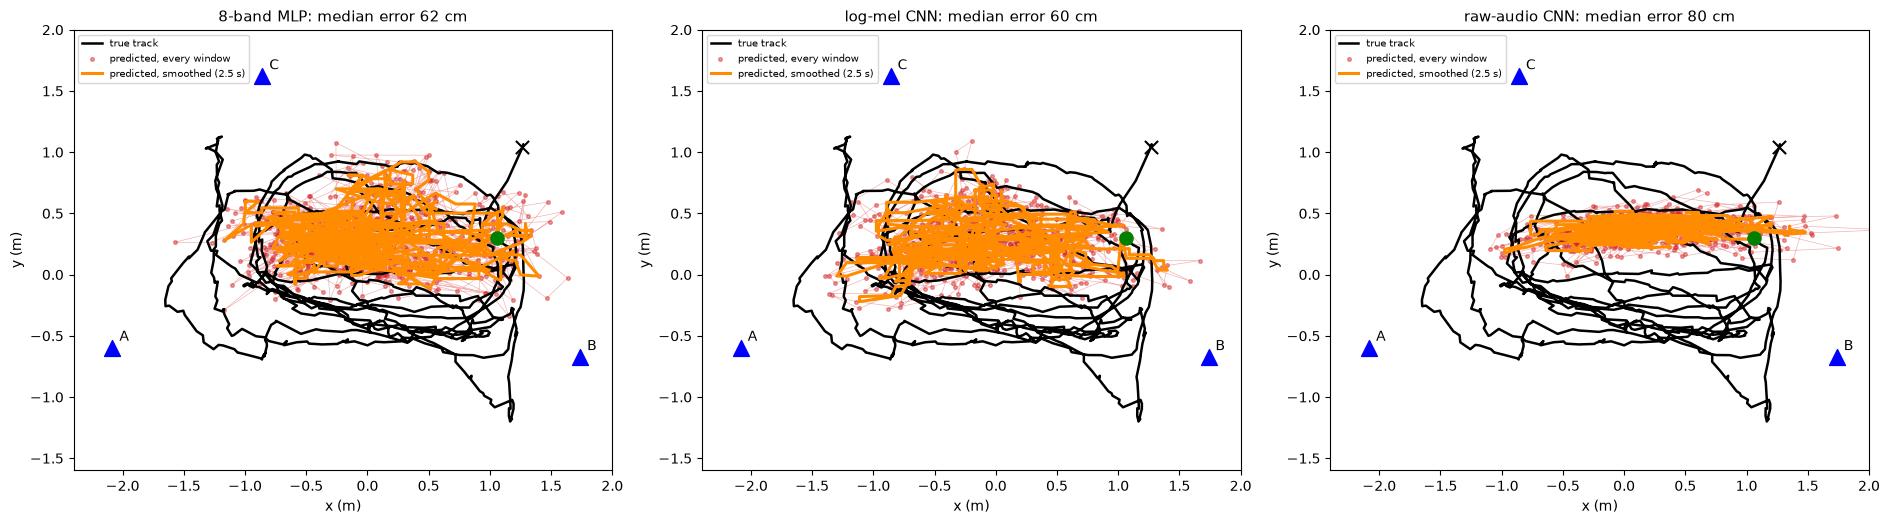

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(19, 6.2))
for a, (name, r) in zip(ax, models3.items()):
    p = r["pred"]; ps = smooth(p)
    a.plot(*te_truth.T, "k-", lw=1.8, label="true track", zorder=3)
    a.plot(*p.T, "-", c="tab:red", lw=0.5, alpha=0.35, zorder=1); a.scatter(*p.T, s=7, c="tab:red", alpha=0.45, label="predicted, every window", zorder=2)
    a.plot(*ps.T, "-", c="darkorange", lw=2.2, label="predicted, smoothed (2.5 s)", zorder=4)
    a.scatter(*te_truth[0], s=90, c="green", zorder=5); a.scatter(*te_truth[-1], s=90, c="k", marker="x", zorder=5)
    for ph, (px, py) in ds.phones.items():
        a.scatter(px, py, marker="^", s=130, c="b", zorder=5); a.annotate(ph, (px, py), xytext=(5, 5), textcoords="offset points")
    a.set_aspect("equal"); a.set_xlim(-2.4, 2.0); a.set_ylim(-1.6, 2.0); a.set_xlabel("x (m)"); a.set_ylabel("y (m)")
    a.set_title(f"{name}: median error {np.median(r['test']):.0f} cm", fontsize=11); a.legend(fontsize=7, loc="upper left")
plt.tight_layout()

### Familiar ground against new ground
Sessions 1 and 2 walked a box of 3.0 x 1.6 m. Session 3 left it at the front of the room, where the earlier sessions never went. A model that has only seen the box cannot answer outside it (its predictions are a function of what it learned inside), so the test splits naturally into windows **inside** the walked box and windows **outside** it.

In [30]:
inside = ((te_truth >= lo) & (te_truth <= hi)).all(1)
print(f"session-3 windows inside the box walked in sessions 1+2: {inside.sum()} of {len(te_truth)} ({inside.mean():.0%}); outside: {(~inside).sum()}\n")
print(f"{'':<16}{'median, inside':>16}{'median, outside':>17}{'y error, inside':>17}{'y error, outside':>18}")
mp = np.linalg.norm(Y[fit_idx].mean(0) - te_truth, axis=1) * 100
print(f"{'mean position':<16}{np.median(mp[inside]):16.0f}{np.median(mp[~inside]):17.0f}")
for k, r in models3.items():
    e = np.linalg.norm(r["pred"] - te_truth, axis=1) * 100; ey = np.abs(r["pred"][:, 1] - te_truth[:, 1]) * 100
    print(f"{k:<16}{np.median(e[inside]):16.0f}{np.median(e[~inside]):17.0f}{np.median(ey[inside]):14.0f} cm{np.median(ey[~inside]):15.0f} cm")
p8 = models3["8-band MLP"]["pred"]
print(f"\npredicted y (8-band MLP) runs from {p8[:, 1].min():.2f} to {p8[:, 1].max():.2f} m; the true session-3 y runs from {te_truth[:, 1].min():.2f} to {te_truth[:, 1].max():.2f} m")

session-3 windows inside the box walked in sessions 1+2: 579 of 826 (70%); outside: 247

                  median, inside  median, outside  y error, inside  y error, outside
mean position                 89              115
8-band MLP                    51               90            28 cm             66 cm
log-mel CNN                   48               82            23 cm             69 cm
raw-audio CNN                 66               98            39 cm             84 cm

predicted y (8-band MLP) runs from -0.34 to 1.08 m; the true session-3 y runs from -1.20 to 1.13 m


## Verdict: how good is it, really?
All numbers are for session 3 (median error in cm unless stated). The smoothed column is after the 5-window running median.

| | median | within 50 cm | within 100 cm | 3x3 zone correct | smoothed median |
|---|---|---|---|---|---|
| blind guess (knows the route, hears nothing) | 118 | 12% | 39% | 11% | |
| mean position | 98 | 10% | 53% | 5% | 98 |
| raw-audio CNN | 80 | 21% | 73% | 13% | 80 |
| 8-band MLP | 62 | 37% | 79% | 34% | 58 |
| **log-mel CNN** | **60** | **40%** | **83%** | **37%** | 58 |

| median error (cm) | windows inside the walked box (70%) | outside it (30%) | y error, inside / outside |
|---|---|---|---|
| mean position | 89 | 115 | |
| 8-band MLP | 51 | 90 | 28 / 66 |
| log-mel CNN | 48 | 82 | 23 / 69 |
| raw-audio CNN | 66 | 98 | 39 / 84 |

**So: real, but modest.** The two best models are clearly *not* just "not so sucky" and clearly *not* a tracker.
* **Clearly better than chance.** About 3 times as many windows are within 50 cm as for a blind guess (37-40% against 12%), the 3x3 zone is right about a third of the time against 11% by chance, and the median is about a third lower than the mean-position answer. This is not an accident of where you walked.
* **But not a tracker.** The track plots show the predictions as a **blob around the middle of the room** (x about -1 to 1 m, y about 0 to 0.5 m) that does not follow the loops of the true path. The 5-window smoothing barely helps (60 -> 58 cm), which says the errors are systematic and not noise that averages away.
* **Left-right works, front-back mostly does not.** R-squared is 0.49-0.57 for x and about 0 for y. The phones A and B sit left and right of the walked area, so the balance between them changes with x. Part of the low y score is not a failure to hear: **inside the box walked in sessions 1+2, the y error is only 23-28 cm**; the damage comes from the 30% of windows where session 3 went below y = -0.35 m, where the models cannot predict at all (their y runs from -0.34 to 1.08 m while the truth runs to -1.20 m).
* **So the real capability is interpolation, not extrapolation.** Inside familiar ground: about 50 cm (against 89 cm for the mean position) in a 3.0 x 1.6 m box, i.e. roughly a body width and a third of the box's width. On new ground: 82-90 cm, only a little better than the mean position (115 cm). That matches the fingerprint view: the model recognises where it has been, it does not know acoustics well enough to reach where it has not.
* **A rough one-line summary for the write-up:** with three phones on the floor, a small model can tell which part of the walked area the speaker is in (left or right, roughly where in the middle) to about 50 cm, far better than chance, but it cannot reproduce the path, and it cannot go beyond the area it was trained on.

## Notes for the experiments

* With `STEP_LEN < WINDOW_LEN` neighbouring windows overlap, so **never split train/test by random window**: a test window would share most of its audio with a training window. Split by contiguous time blocks (or by session).
* The windows only cover where the speaker walked, mostly the middle of the room (see the map). Errors outside it are extrapolation.
* Clock drift between the phones is uncorrected, so later parts of a session are a bit less reliable.
* Part 4 (grey-box features, train/validate on sessions 1+2, test on session 3) is the first approach that beats the baseline: 8-band levels give a median error of about 62 cm against 98 cm on the held-out session 3. See its caveats before quoting it.
* 4b and Part 5: a small CNN on log-mel spectrograms (60 cm) is no better than the 8-band MLP (62 cm); a small raw-audio CNN reaches 80 cm; the baseline is 98 cm. Less built in by hand means a worse result at this data size.
* Trained models are not saved yet; planned for the end of the study session.

# Discussion: what the feasibility pass suggests, and where it points next
*(The author's reading after Parts 1-5. Each point is tagged with what the data here does and does not show.)*

## Overall
As a feasibility test, a few phones on the floor carry **some usable information about where a speaker is in a room**. Timing between phones (GCC-PHAT) failed, but the frequency balance between phones lets a small model place the speaker to about 50 cm inside the area it was trained on, well above chance. The route from here is to use these insights to design a set-up closer to the project's real goal: **identifying several speakers and tracking them in a room, in order to model their interactions.**

## Insights
1. **Room-specific adaptation of a general model.** The models show a basic ability to say roughly where the speaker is, which hints at a relatively general ("foundational") model that is tuned for a specific room with very little data (one-shot or few-shot), as a possible part of the final project.
   *What the data say:* the models here were trained on this room only and are room-specific fingerprints. Nothing in this notebook tests transfer between rooms or adaptation from a few examples; that would need recordings from several rooms and a pre-training step. So this is a motivation, not a result.

2. **The y axis looks promising, perhaps because of the phone layout.** Inside the area walked in sessions 1+2, the y error is only 23-28 cm, and the phones cover a good distance along y; more, better-spread microphones (for example four or more) might help on both axes.
   *What the data say:* the y figure is real but partly expected, since the walked box is only 1.6 m in y against 3.0 m in x, so a smaller absolute y error is to be expected; the x error inside the box was not reported separately. Overall R-squared for y is about 0 because the model cannot answer outside the trained range (see the verdict), not because it fails to hear y. That the phone positions explain the pattern is a hypothesis, not tested. Testing how much each phone contributes is easy with the current data (drop one channel and re-score); testing a different layout needs a new recording.

3. **Predict zones, not exact positions.** The current target is the exact position, which is a harder task than needed. Relaxing it to zones (the room cut into small squares, for example 20 cm by 20 cm) may be easier for the model.
   *What the data say:* the trade-off is the zone size against the error. The current median error is about 50-60 cm, which is larger than a 20 cm cell, so 20 cm cells would be classified wrongly most of the time and would not be easier; the benefit appears when the zone is about as large as the error. For reference, the 3x3 grid used above (cells about 1.0 x 0.5 m) is right 34-37% of the time against 11% by chance. How accuracy changes with zone size, and whether classification beats regression at equal cell size, is untested and cheap to test on the existing data.

## Follow-up questions
* **How does the spacing of the microphones affect performance?** Not testable with the three fixed positions recorded here. Can be approached by dropping channels (two against three phones) now, and by recording the same session with phones at different spacings later.
* **How does the type of label (true location against zone) affect performance?** Testable now: same features and models, with exact-position regression compared against zone classification at several cell sizes, scored on the same session 3 with the same rules.
* **Does microphone heterogeneity help or disturb?** I.e. is the model better off when the microphones differ intrinsically (different models, gains, placement against walls)? The features here subtract the average over the phones, which assumes equal gain, and a fingerprint model absorbs constant differences of that kind; whether differences help (they make the three channels more distinct) or hurt (they break the assumption of comparable levels, and a new device would shift the fingerprint) has not been tested. Needs recordings with deliberately different microphones, or a simulation that applies different gains or equalisation to the channels.

## Where this points
The set-up that matches the project's goal: more, well-spread microphones, a target that is a zone (or the identity of the zone) instead of an exact point, per-room adaptation, and then several simultaneous speakers, which this single-speaker test did not touch at all. What the current set-up cannot answer should be listed explicitly: separating and locating **overlapping** speakers, speaker identity, other rooms and days, and moving the microphones.